# **Processed Dataset Exploratory Data Analysis (EDA)**

This Exploratory Data Analysis (EDA) notebook aims to examine the processed data after feature analysis to determine all the Scikit-Learn preprocessing tools required for model Pipeline construction. 

## **Load Datasets & Dependencies**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns

from src.config import load_config

In [2]:
config = load_config()
df = pd.read_parquet(config.data.processed_path)

In [3]:
# Style and font size for graphical EDA visualisations
style.use("ggplot")
FIGURE_TITLE = 14
GRAPH_TITLE = 12
AXIS_LABELS = 8
TICKS = 6

## **Dataset Overview**

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17857 entries, 0 to 17856
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customer_id              17857 non-null  int64         
 1   cutoff                   17857 non-null  datetime64[us]
 2   churn_horizon            17857 non-null  int64         
 3   recency                  17857 non-null  int64         
 4   frequency                17857 non-null  int64         
 5   monetary                 17857 non-null  float64       
 6   mean_order_value         17857 non-null  float64       
 7   tenure                   17857 non-null  int64         
 8   avg_inter_purchase_gap   13775 non-null  float64       
 9   std_inter_purchase_gap   10632 non-null  float64       
 10  recency_ratio            13576 non-null  float64       
 11  spend_30d                17857 non-null  float64       
 12  spend_90d                17857 non-null  fl

In [5]:
df.describe()

,customer_id,cutoff,churn_horizon,recency,frequency,monetary,mean_order_value,tenure,avg_inter_purchase_gap,std_inter_purchase_gap,...,orders_90d,orders_150d,spend_momentum_30d_90d,spend_momentum_90d_150d,order_momentum_30d_90d,order_momentum_90d_150d,distinct_products,mean_order_quantity,return_rate,churned
count,17857.000000,17857,17857.0,17857.000000,17857.000000,17857.000000,17857.000000,17857.000000,13775.000000,10632.000000,...,17857.000000,17857.000000,14152.000000,17857.000000,14152.000000,17857.000000,17857.000000,17857.000000,17857.000000,17857.000000
mean,15318.102201,2011-01-04 04:19:54.287954,150.0,53.772862,5.585373,2630.331768,391.013278,235.439044,73.464226,44.606676,...,1.694182,2.661309,0.959393,1.061537,0.972203,1.063664,77.137201,267.883503,0.124442,0.428011
min,12346.000000,2010-10-01 00:00:00,150.0,1.000000,1.000000,2.900000,2.900000,1.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,13861.000000,2010-11-01 00:00:00,150.0,19.000000,2.000000,412.080000,193.480000,106.000000,31.000000,18.753673,...,1.000000,1.000000,0.000000,0.557792,0.000000,0.666667,22.000000,98.000000,0.000000,0.000000
50%,15298.000000,2010-12-01 00:00:00,150.0,46.000000,3.000000,967.930000,299.827500,241.000000,54.666667,33.364652,...,1.000000,2.000000,0.000000,1.233303,0.000000,1.176471,48.000000,164.000000,0.000000,0.000000
75%,16788.000000,2011-02-01 00:00:00,150.0,82.000000,6.000000,2220.090000,437.400000,335.000000,93.833333,59.018945,...,2.000000,3.000000,1.821425,1.666667,1.500000,1.666667,98.000000,271.000000,0.250000,1.000000
max,18287.000000,2011-07-12 00:00:00,150.0,150.000000,253.000000,441213.290000,25784.320000,588.000000,539.000000,354.967604,...,80.000000,100.000000,3.000000,1.666667,3.000000,1.666667,2052.000000,87167.000000,0.833333,1.000000
std,1695.013066,NaN,0.0,40.286199,9.525933,10770.301327,534.783598,146.271261,64.564102,37.753250,...,2.647962,3.914933,1.207214,0.657814,1.199137,0.648394,97.942475,1560.048779,0.165894,0.494804


In [6]:
df.head(10)

,customer_id,cutoff,churn_horizon,recency,frequency,monetary,mean_order_value,tenure,avg_inter_purchase_gap,std_inter_purchase_gap,...,orders_150d,spend_momentum_30d_90d,spend_momentum_90d_150d,order_momentum_30d_90d,order_momentum_90d_150d,distinct_products,mean_order_quantity,return_rate,country,churned
0,12346,2010-10-01,150,95,2,169.36,84.680000,213,118.00,NaN,...,1,NaN,0.000000,NaN,0.000000,24,12.0,0.000000,United Kingdom,0
1,12348,2010-10-01,150,4,1,221.16,221.160000,4,NaN,NaN,...,1,3.0,1.666667,3.0,1.666667,19,372.0,0.000000,Finland,0
2,12355,2010-10-01,150,133,1,488.21,488.210000,133,NaN,NaN,...,1,NaN,0.000000,NaN,0.000000,22,303.0,0.000000,Bahrain,1
3,12358,2010-10-01,150,116,2,1697.93,848.965000,297,181.00,NaN,...,1,NaN,0.000000,NaN,0.000000,34,295.0,0.000000,Austria,0
4,12359,2010-10-01,150,101,5,2012.03,402.406000,300,49.25,42.648759,...,1,NaN,0.000000,NaN,0.000000,82,175.4,0.285714,Cyprus,0
5,12360,2010-10-01,150,129,2,620.04,310.020000,221,92.00,NaN,...,1,NaN,0.000000,NaN,0.000000,43,376.0,0.000000,Austria,0
6,12361,2010-10-01,150,28,3,276.35,92.116667,248,109.50,9.192388,...,2,3.0,0.905847,3.0,0.833333,13,47.0,0.000000,Belgium,0
7,12369,2010-10-01,150,15,2,1367.80,683.900000,207,192.00,NaN,...,1,3.0,1.666667,3.0,1.666667,81,574.5,0.000000,Austria,0
8,12378,2010-10-01,150,128,1,1407.70,1407.700000,128,NaN,NaN,...,1,NaN,0.000000,NaN,0.000000,82,787.0,0.000000,Switzerland,1
9,12379,2010-10-01,150,100,1,322.48,322.480000,100,NaN,NaN,...,1,NaN,0.000000,NaN,0.000000,17,160.0,0.000000,Belgium,0


In [7]:
df.duplicated().sum()

np.int64(0)

## **Missing Value Analysis**

In [8]:
df.isna().sum()

customer_id                   0
cutoff                        0
churn_horizon                 0
recency                       0
frequency                     0
monetary                      0
mean_order_value              0
tenure                        0
avg_inter_purchase_gap     4082
std_inter_purchase_gap     7225
recency_ratio              4281
spend_30d                     0
spend_90d                     0
spend_150d                    0
orders_30d                    0
orders_90d                    0
orders_150d                   0
spend_momentum_30d_90d     3705
spend_momentum_90d_150d       0
order_momentum_30d_90d     3705
order_momentum_90d_150d       0
distinct_products             0
mean_order_quantity           0
return_rate                   0
country                       0
churned                       0
dtype: int64

**Missing Values:**

- ***avg_inter_purchase_gap***. To be expected; affects customers with only 1 purchase in their observation window.

- ***std_inter_purchase_gap***. To be expected; affects customers with 2 or less purchases in their observation window.

- ***recency_ratio***. To be expected; affects customers with only 1 purchase in their observation window **OR** with all their purchases on the same day.

- ***spend_momentum_30d_90d***. To be expected; affects customers who had no purchase activities within 90 days before the cutoff.

- ***order_momentum_30d_90d***. To be expected; affects customers who did not make any orders within 90 days before the cutoff.

## **Univariate Analysis**

### **RFM Features**

In [9]:
df[["recency", "frequency", "monetary", "mean_order_value"]].describe()

,recency,frequency,monetary,mean_order_value
count,17857.000000,17857.000000,17857.000000,17857.000000
mean,53.772862,5.585373,2630.331768,391.013278
std,40.286199,9.525933,10770.301327,534.783598
min,1.000000,1.000000,2.900000,2.900000
25%,19.000000,2.000000,412.080000,193.480000
50%,46.000000,3.000000,967.930000,299.827500
75%,82.000000,6.000000,2220.090000,437.400000
max,150.000000,253.000000,441213.290000,25784.320000


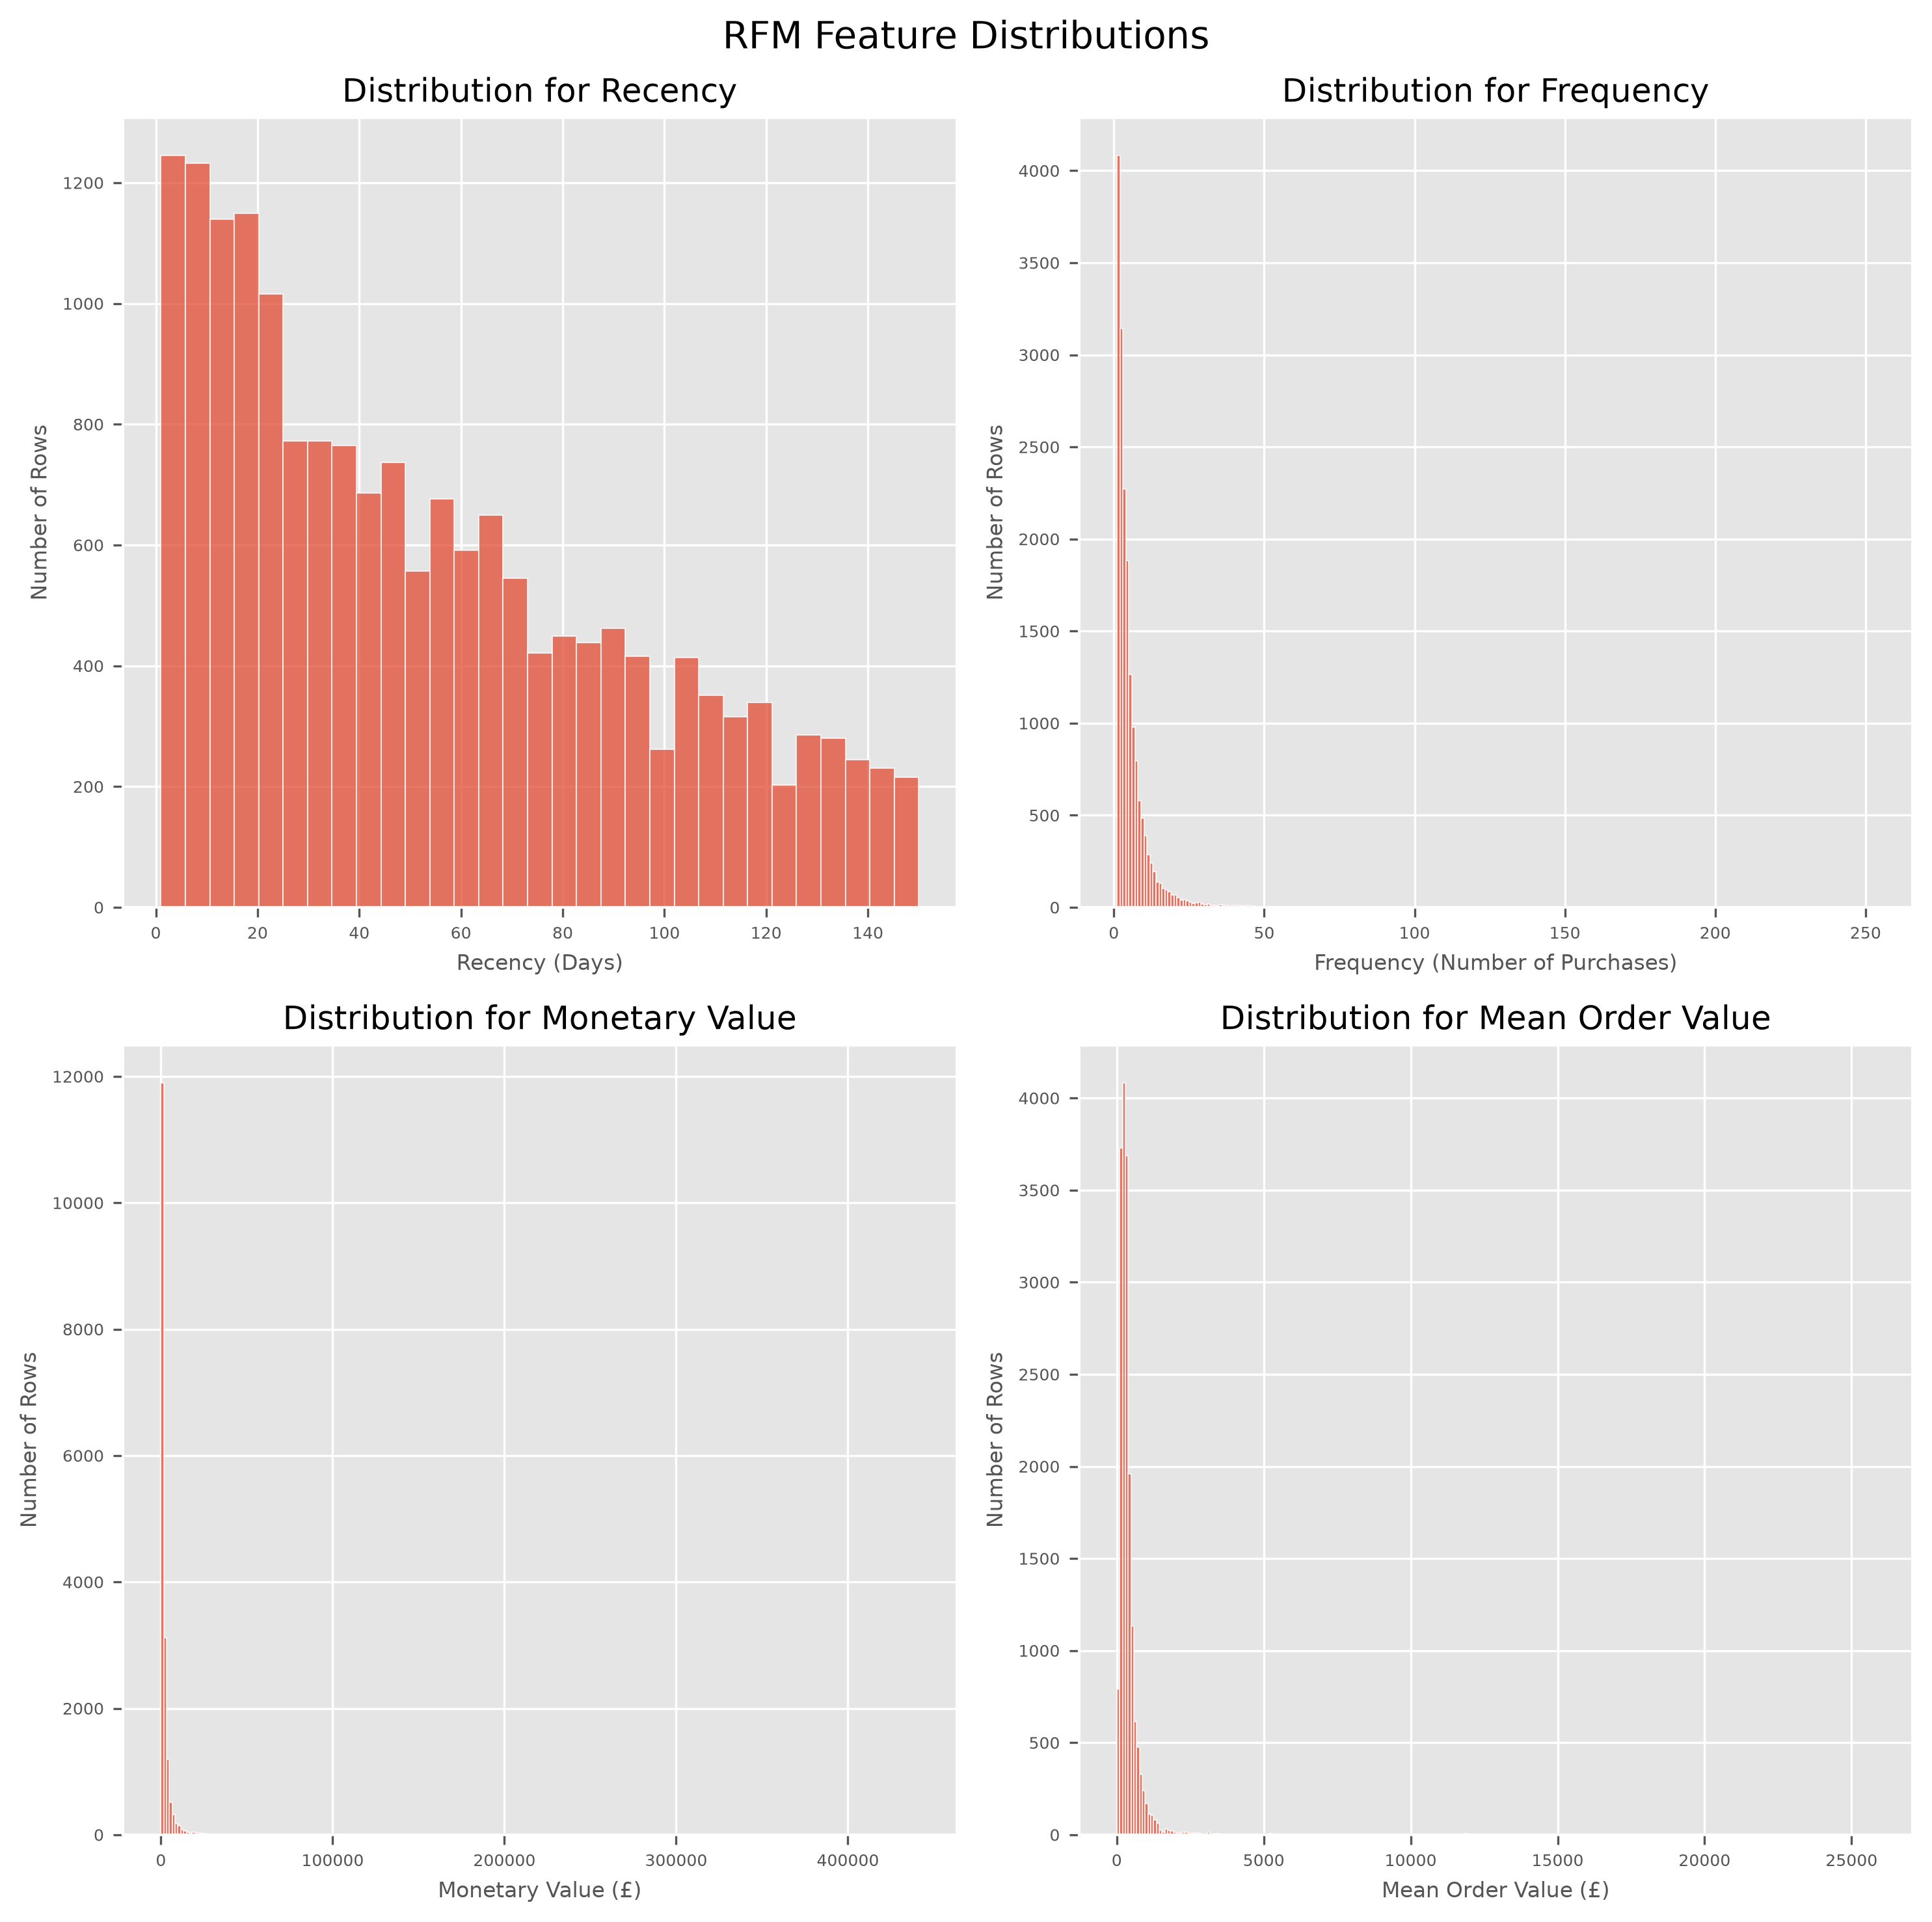

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(10, 10), dpi=300)

ax[0, 0].hist(df["recency"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[0, 0].set_xlabel(f"Recency (Days)", fontsize=AXIS_LABELS)
ax[0, 0].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[0, 0].set_title(f"Distribution for Recency", fontsize=GRAPH_TITLE)
ax[0, 0].tick_params(axis="both", which="major", labelsize=TICKS)

ax[0, 1].hist(df["frequency"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[0, 1].set_xlabel(f"Frequency (Number of Purchases)", fontsize=AXIS_LABELS)
ax[0, 1].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[0, 1].set_title(f"Distribution for Frequency", fontsize=GRAPH_TITLE)
ax[0, 1].tick_params(axis="both", which="major", labelsize=TICKS)

ax[1, 0].hist(df["monetary"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[1, 0].set_xlabel(f"Monetary Value (£)", fontsize=AXIS_LABELS)
ax[1, 0].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[1, 0].set_title(f"Distribution for Monetary Value", fontsize=GRAPH_TITLE)
ax[1, 0].tick_params(axis="both", which="major", labelsize=TICKS)

ax[1, 1].hist(df["mean_order_value"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[1, 1].set_xlabel(f"Mean Order Value (£)", fontsize=AXIS_LABELS)
ax[1, 1].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[1, 1].set_title(f"Distribution for Mean Order Value", fontsize=GRAPH_TITLE)
ax[1, 1].tick_params(axis="both", which="major", labelsize=TICKS)

fig.suptitle("RFM Feature Distributions", fontsize=FIGURE_TITLE)
fig.tight_layout()

### **Tenure**

In [11]:
df["tenure"].describe().to_frame()

,tenure
count,17857.000000
mean,235.439044
std,146.271261
min,1.000000
25%,106.000000
50%,241.000000
75%,335.000000
max,588.000000


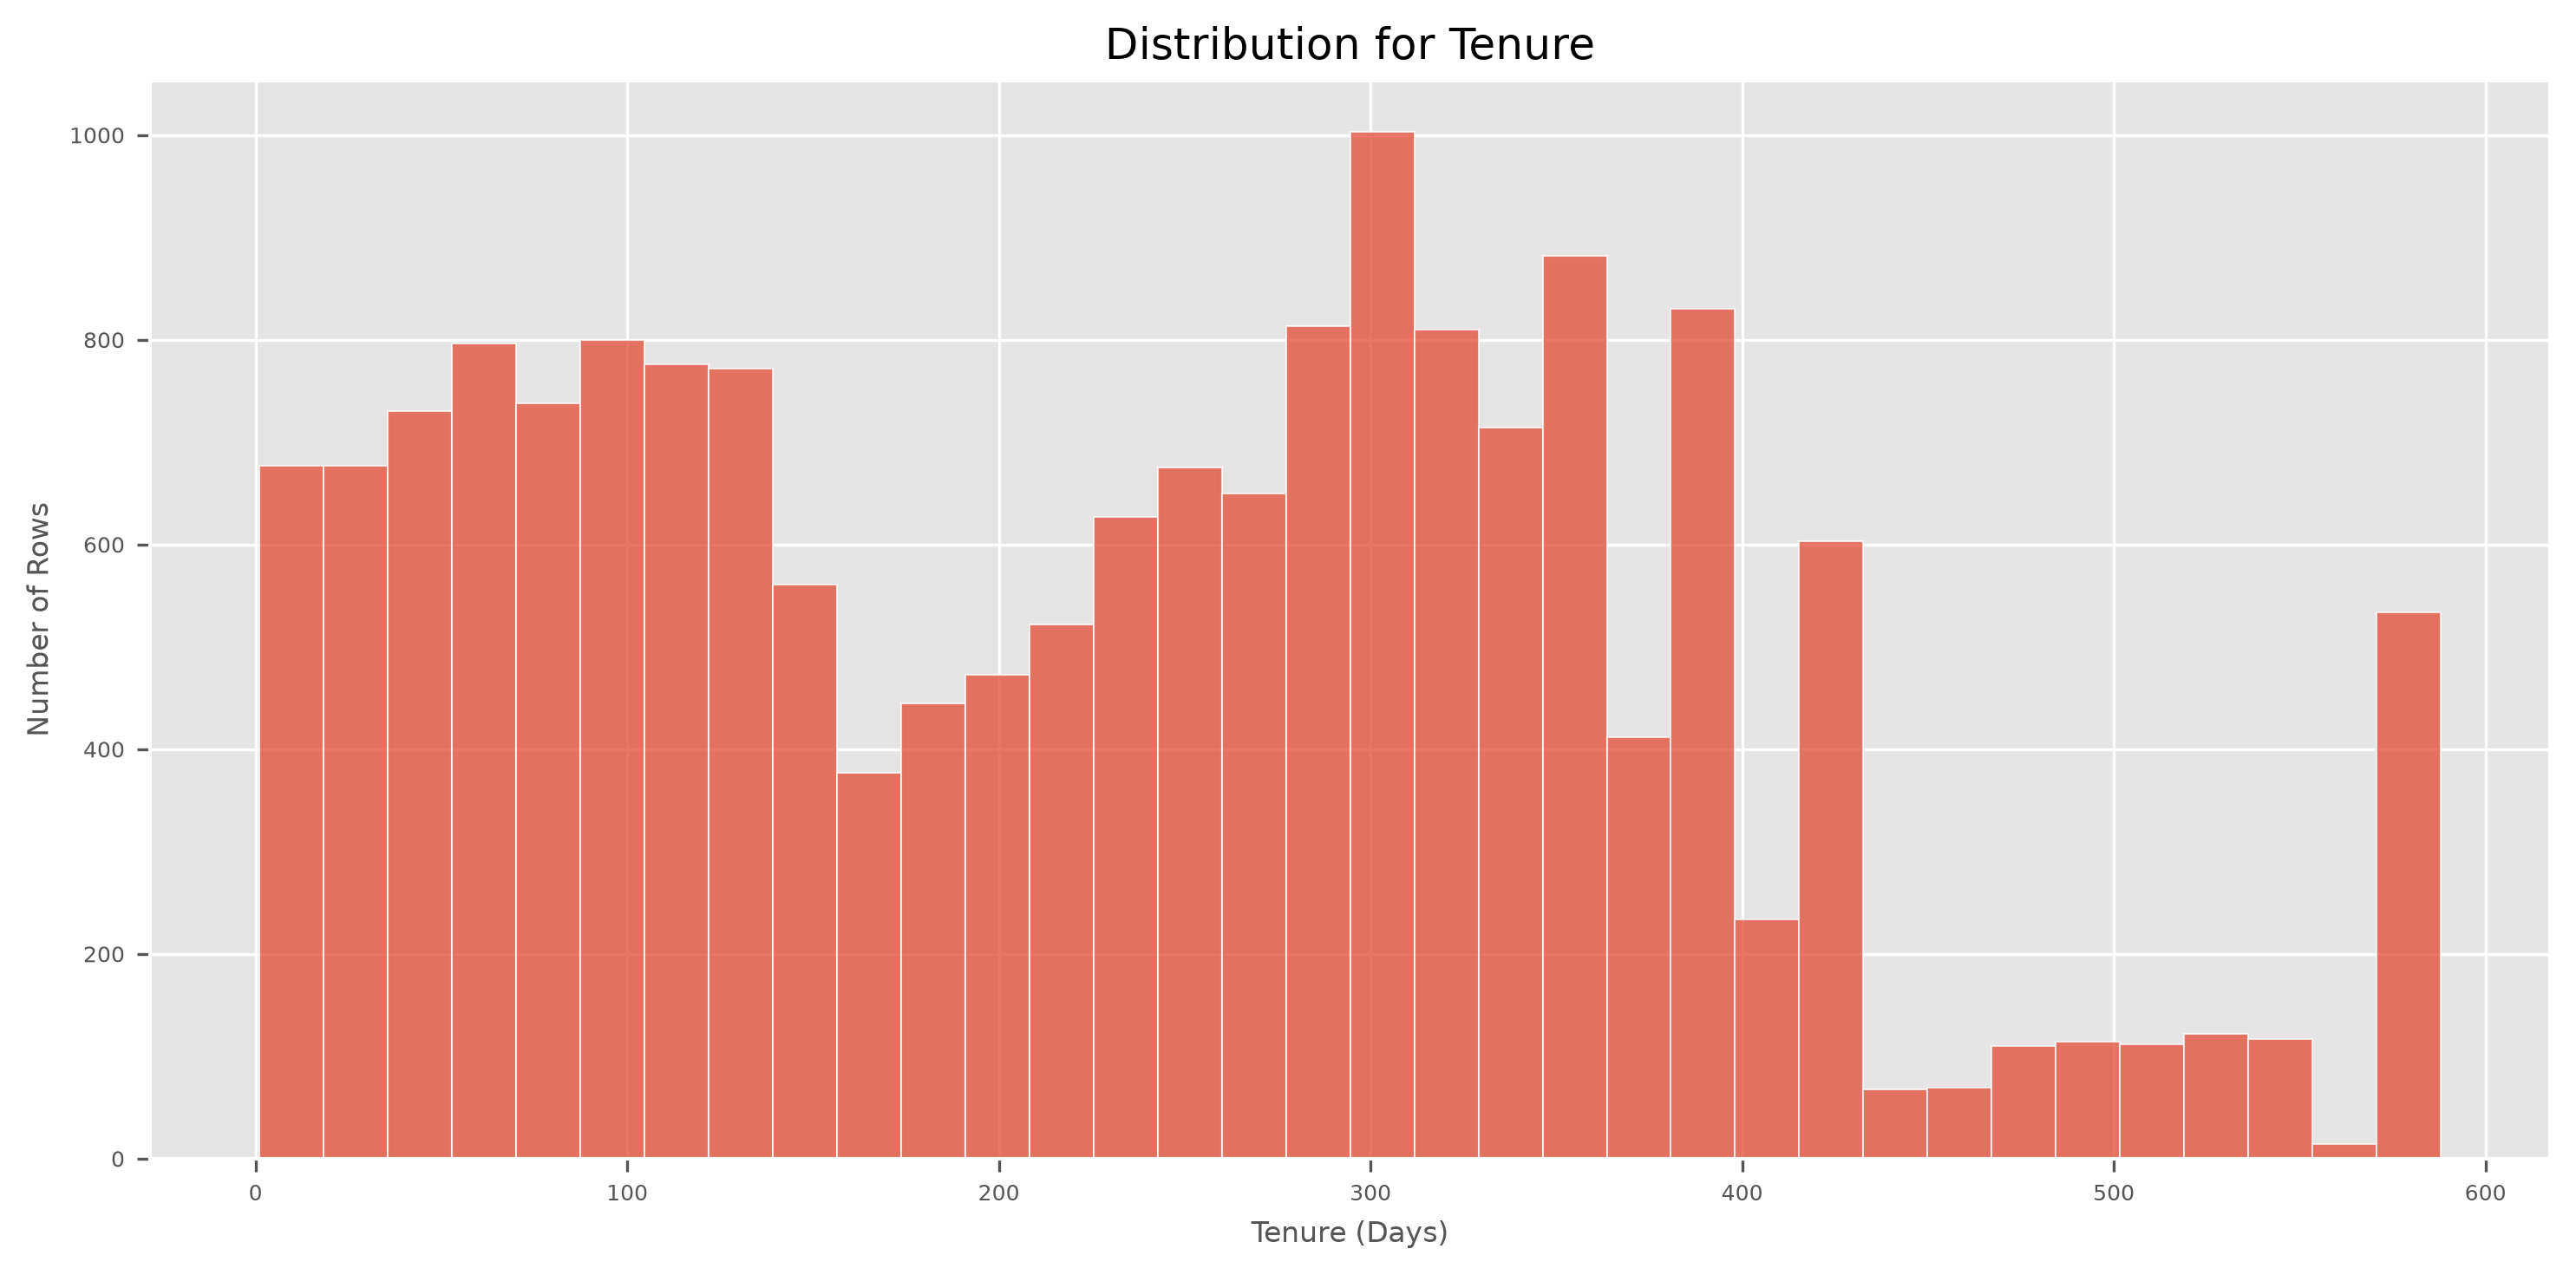

In [12]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.hist(df["tenure"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax.set_xlabel(f"Tenure (Days)", fontsize=AXIS_LABELS)
ax.set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax.set_title(f"Distribution for Tenure", fontsize=GRAPH_TITLE)
ax.tick_params(axis="both", which="major", labelsize=TICKS)
fig.tight_layout()

### **Interval Features**

In [13]:
df[["avg_inter_purchase_gap", "std_inter_purchase_gap", "recency_ratio"]].describe()

,avg_inter_purchase_gap,std_inter_purchase_gap,recency_ratio
count,13775.000000,10632.000000,13576.000000
mean,73.464226,44.606676,1.367509
std,64.564102,37.753250,6.453689
min,0.000000,0.000000,0.002755
25%,31.000000,18.753673,0.293983
50%,54.666667,33.364652,0.669990
75%,93.833333,59.018945,1.345496
max,539.000000,354.967604,378.000000


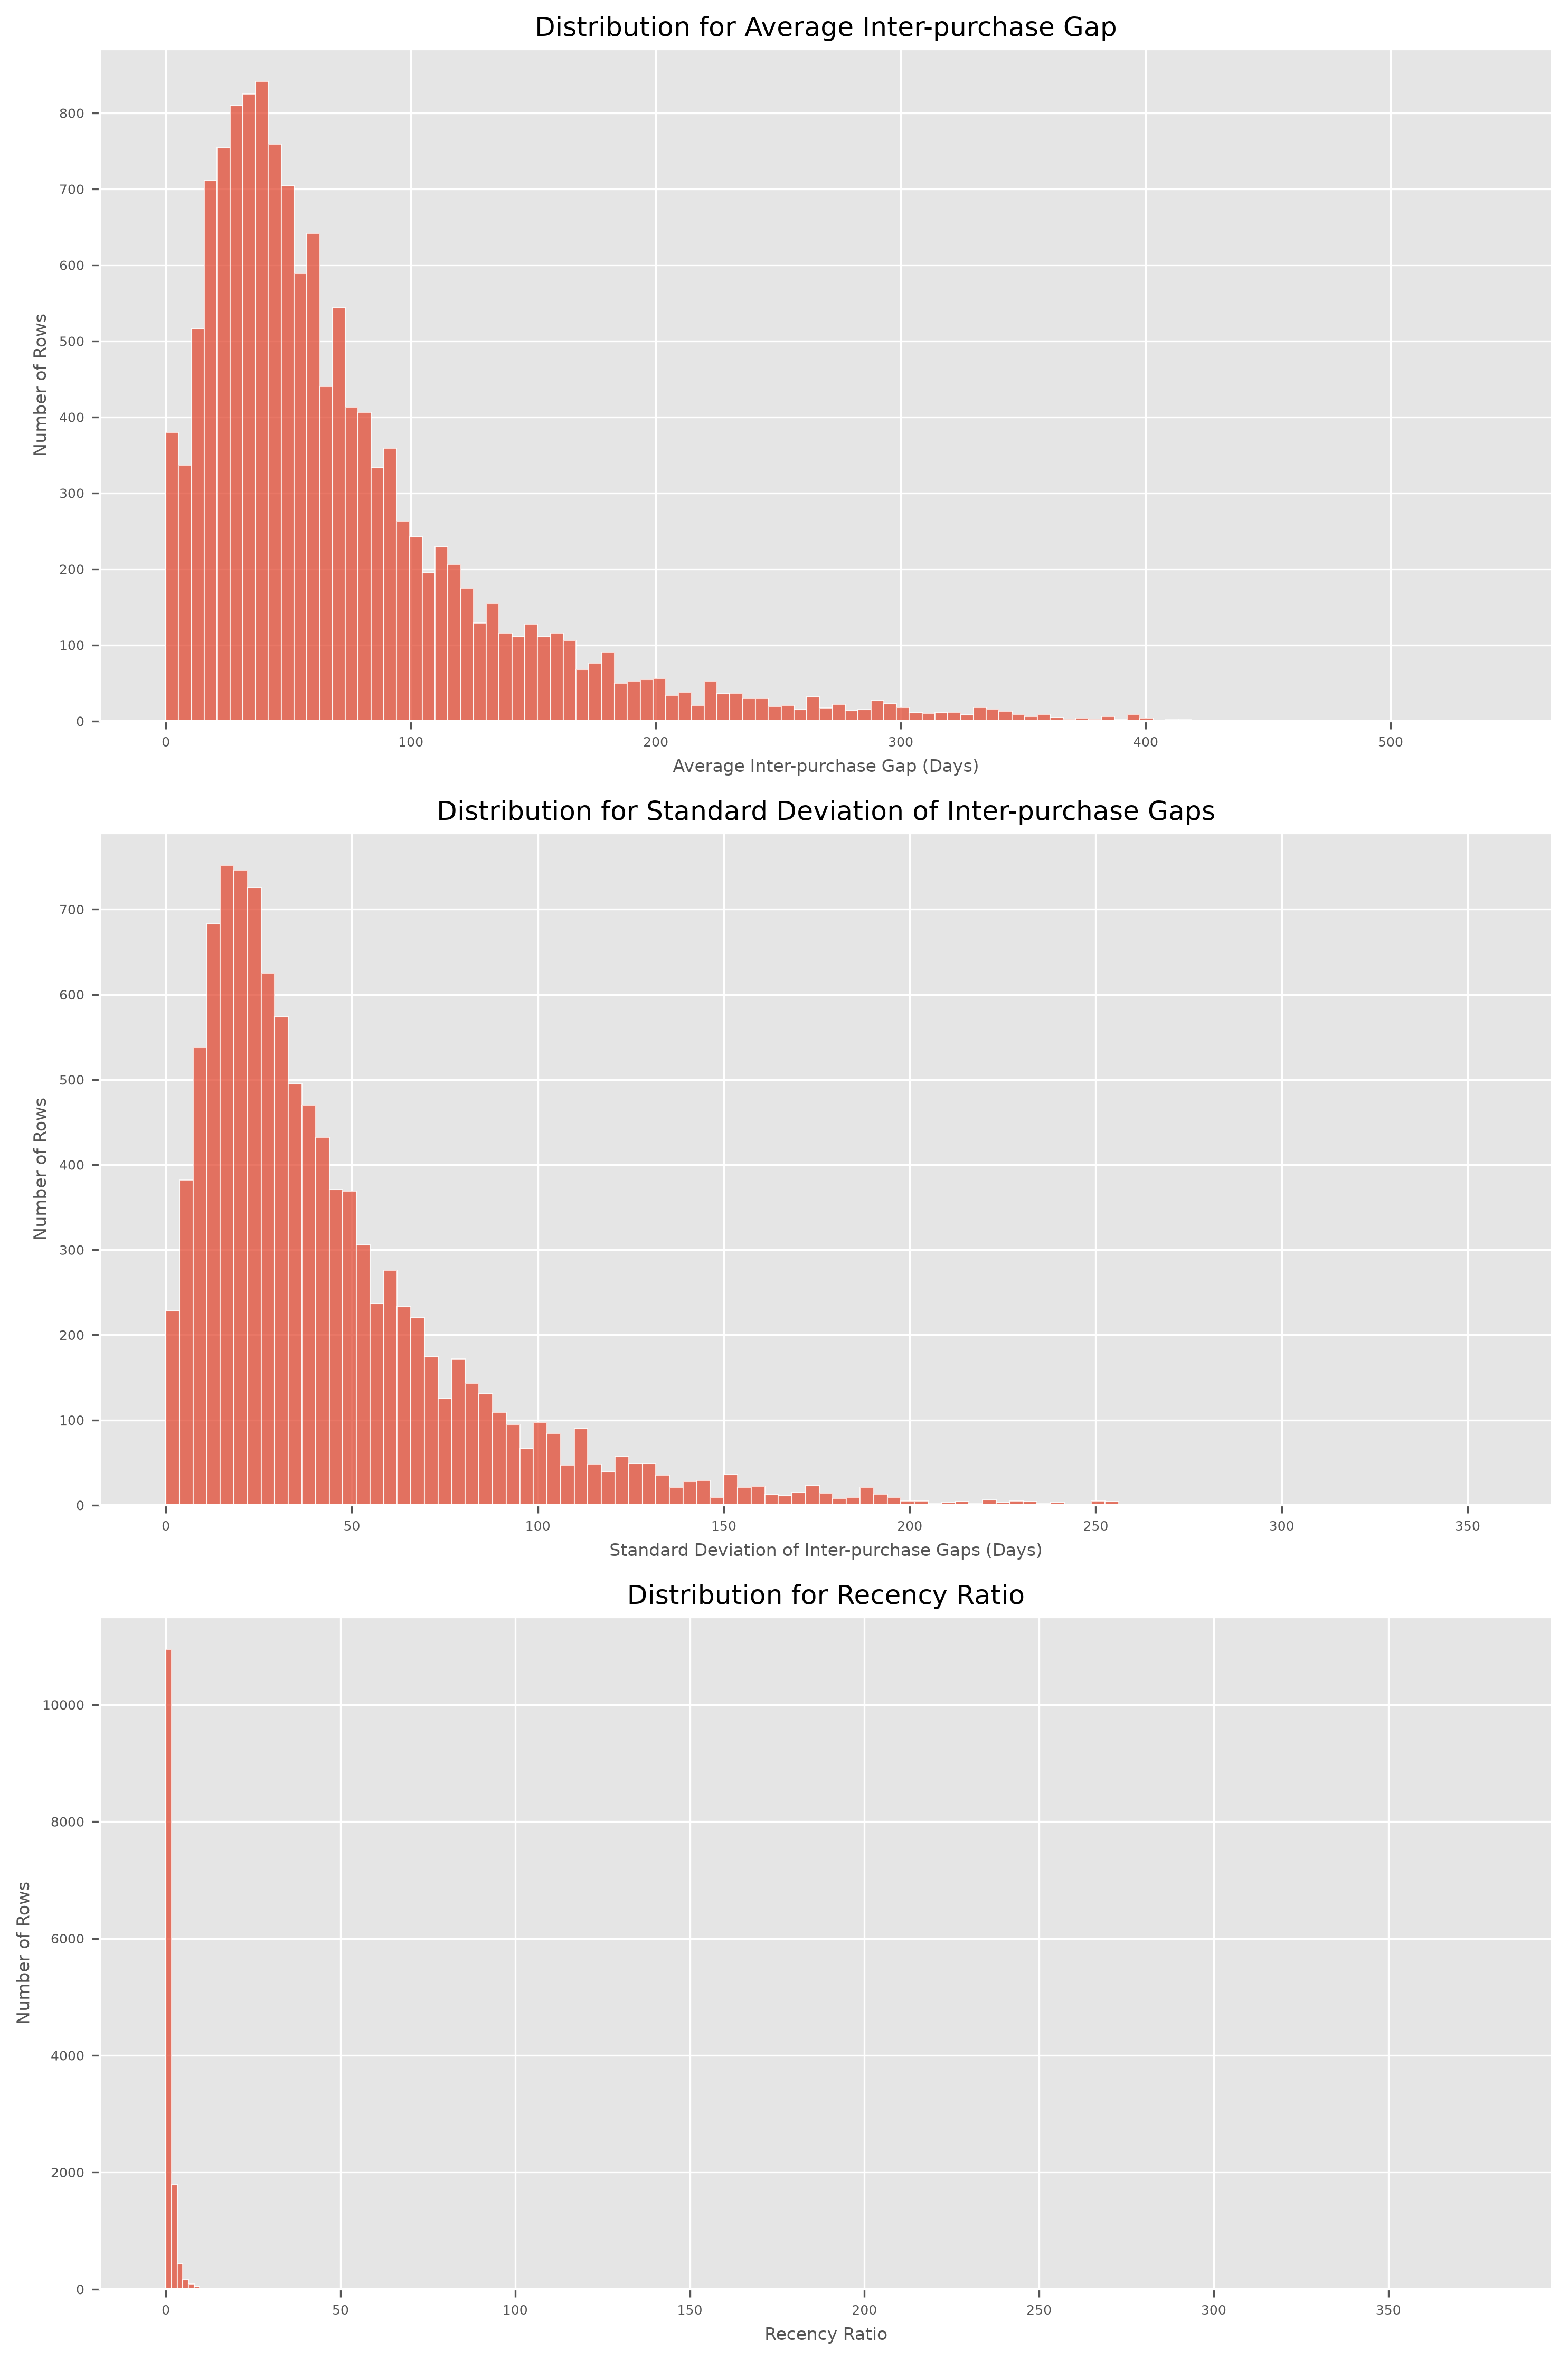

In [14]:
fig, ax = plt.subplots(3, 1, figsize=(10, 15), dpi=300)

ax[0].hist(df["avg_inter_purchase_gap"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[0].set_xlabel(f"Average Inter-purchase Gap (Days)", fontsize=AXIS_LABELS)
ax[0].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[0].set_title(f"Distribution for Average Inter-purchase Gap", fontsize=GRAPH_TITLE)
ax[0].tick_params(axis="both", which="major", labelsize=TICKS)

ax[1].hist(df["std_inter_purchase_gap"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[1].set_xlabel(f"Standard Deviation of Inter-purchase Gaps (Days)", fontsize=AXIS_LABELS)
ax[1].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[1].set_title(f"Distribution for Standard Deviation of Inter-purchase Gaps", fontsize=GRAPH_TITLE)
ax[1].tick_params(axis="both", which="major", labelsize=TICKS)

ax[2].hist(df["recency_ratio"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[2].set_xlabel(f"Recency Ratio", fontsize=AXIS_LABELS)
ax[2].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[2].set_title(f"Distribution for Recency Ratio", fontsize=GRAPH_TITLE)
ax[2].tick_params(axis="both", which="major", labelsize=TICKS)

fig.tight_layout()

### **Activity Features**

In [15]:
df[["spend_30d", "spend_90d", "spend_150d", "spend_momentum_30d_90d", "spend_momentum_90d_150d"]].describe()

,spend_30d,spend_90d,spend_150d,spend_momentum_30d_90d,spend_momentum_90d_150d
count,17857.000000,17857.000000,17857.000000,14152.000000,17857.000000
mean,256.404963,779.214476,1216.634820,0.959393,1.061537
std,1225.738193,2789.296576,4261.272427,1.207214,0.657814
min,0.000000,0.000000,2.900000,0.000000,0.000000
25%,0.000000,108.840000,269.730000,0.000000,0.557792
50%,0.000000,325.450000,512.580000,0.000000,1.233303
75%,264.660000,717.630000,1080.660000,1.821425,1.666667
max,77183.600000,99125.700000,151413.770000,3.000000,1.666667


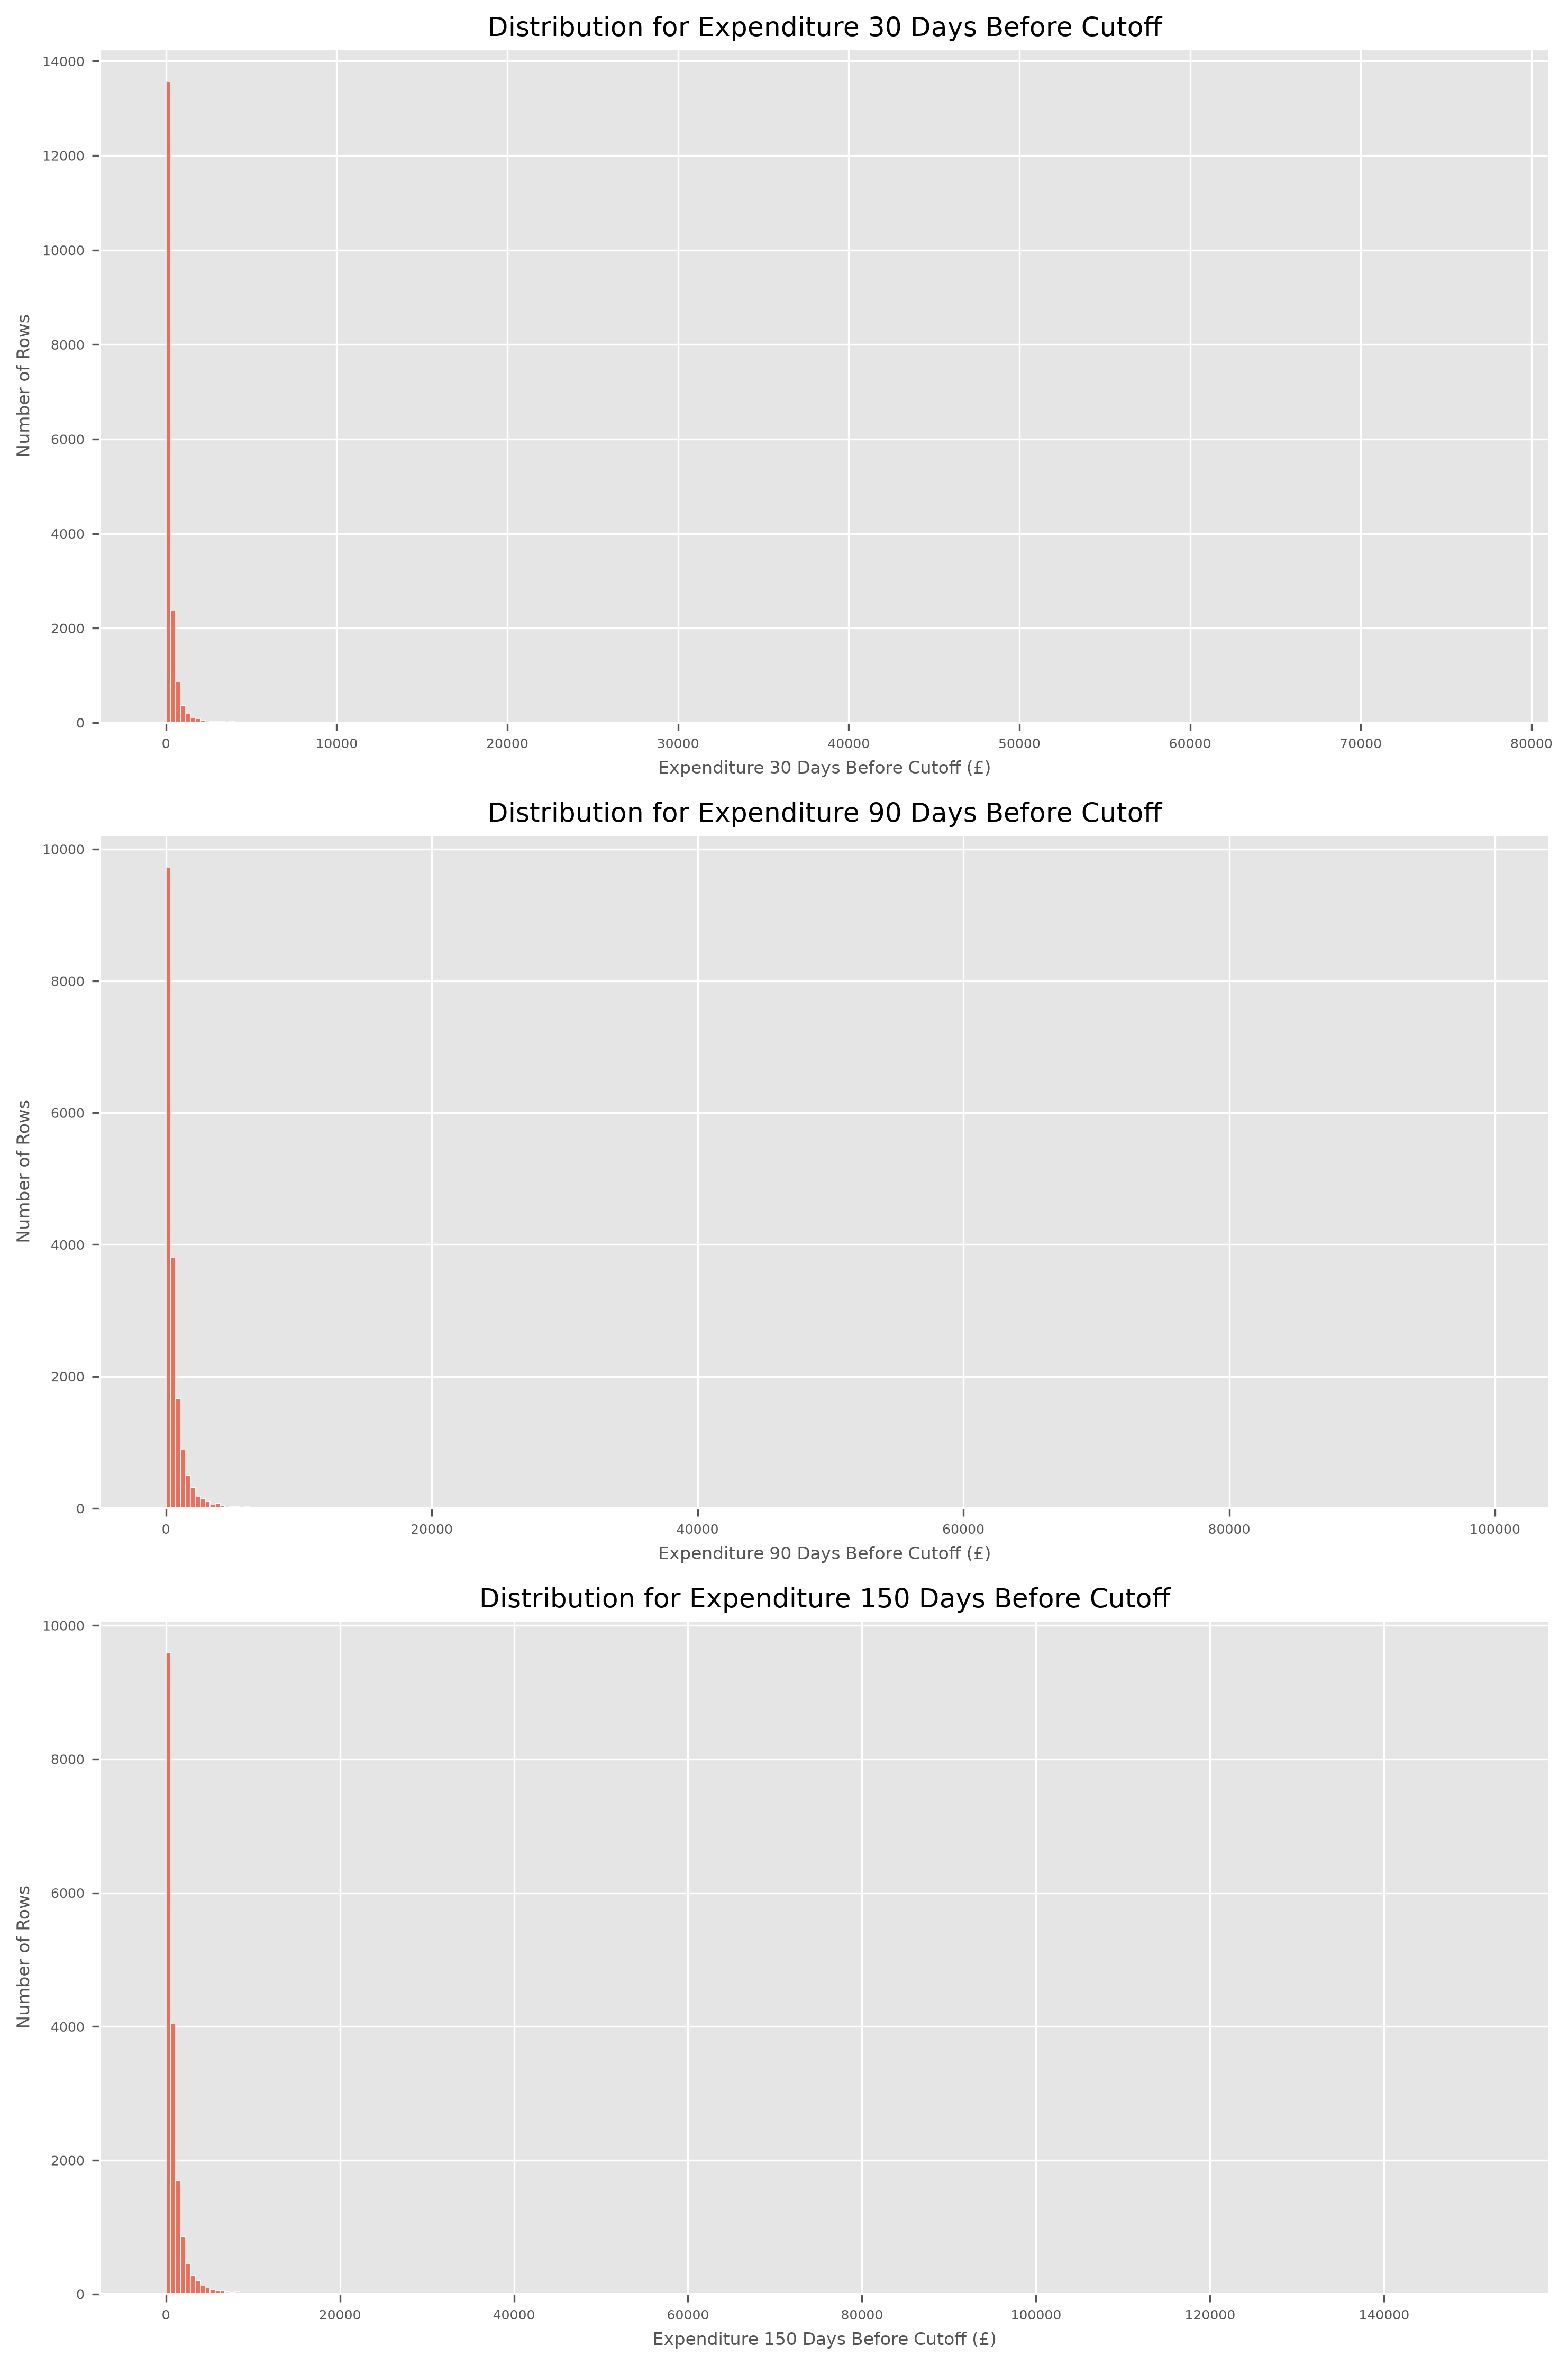

In [16]:
fig, ax = plt.subplots(3, 1, figsize=(10, 15), dpi=300)

ax[0].hist(df["spend_30d"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[0].set_xlabel(f"Expenditure 30 Days Before Cutoff (£)", fontsize=AXIS_LABELS)
ax[0].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[0].set_title(f"Distribution for Expenditure 30 Days Before Cutoff", fontsize=GRAPH_TITLE)
ax[0].tick_params(axis="both", which="major", labelsize=TICKS)

ax[1].hist(df["spend_90d"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[1].set_xlabel(f"Expenditure 90 Days Before Cutoff (£)", fontsize=AXIS_LABELS)
ax[1].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[1].set_title(f"Distribution for Expenditure 90 Days Before Cutoff", fontsize=GRAPH_TITLE)
ax[1].tick_params(axis="both", which="major", labelsize=TICKS)

ax[2].hist(df["spend_150d"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[2].set_xlabel(f"Expenditure 150 Days Before Cutoff (£)", fontsize=AXIS_LABELS)
ax[2].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[2].set_title(f"Distribution for Expenditure 150 Days Before Cutoff", fontsize=GRAPH_TITLE)
ax[2].tick_params(axis="both", which="major", labelsize=TICKS)

fig.tight_layout()

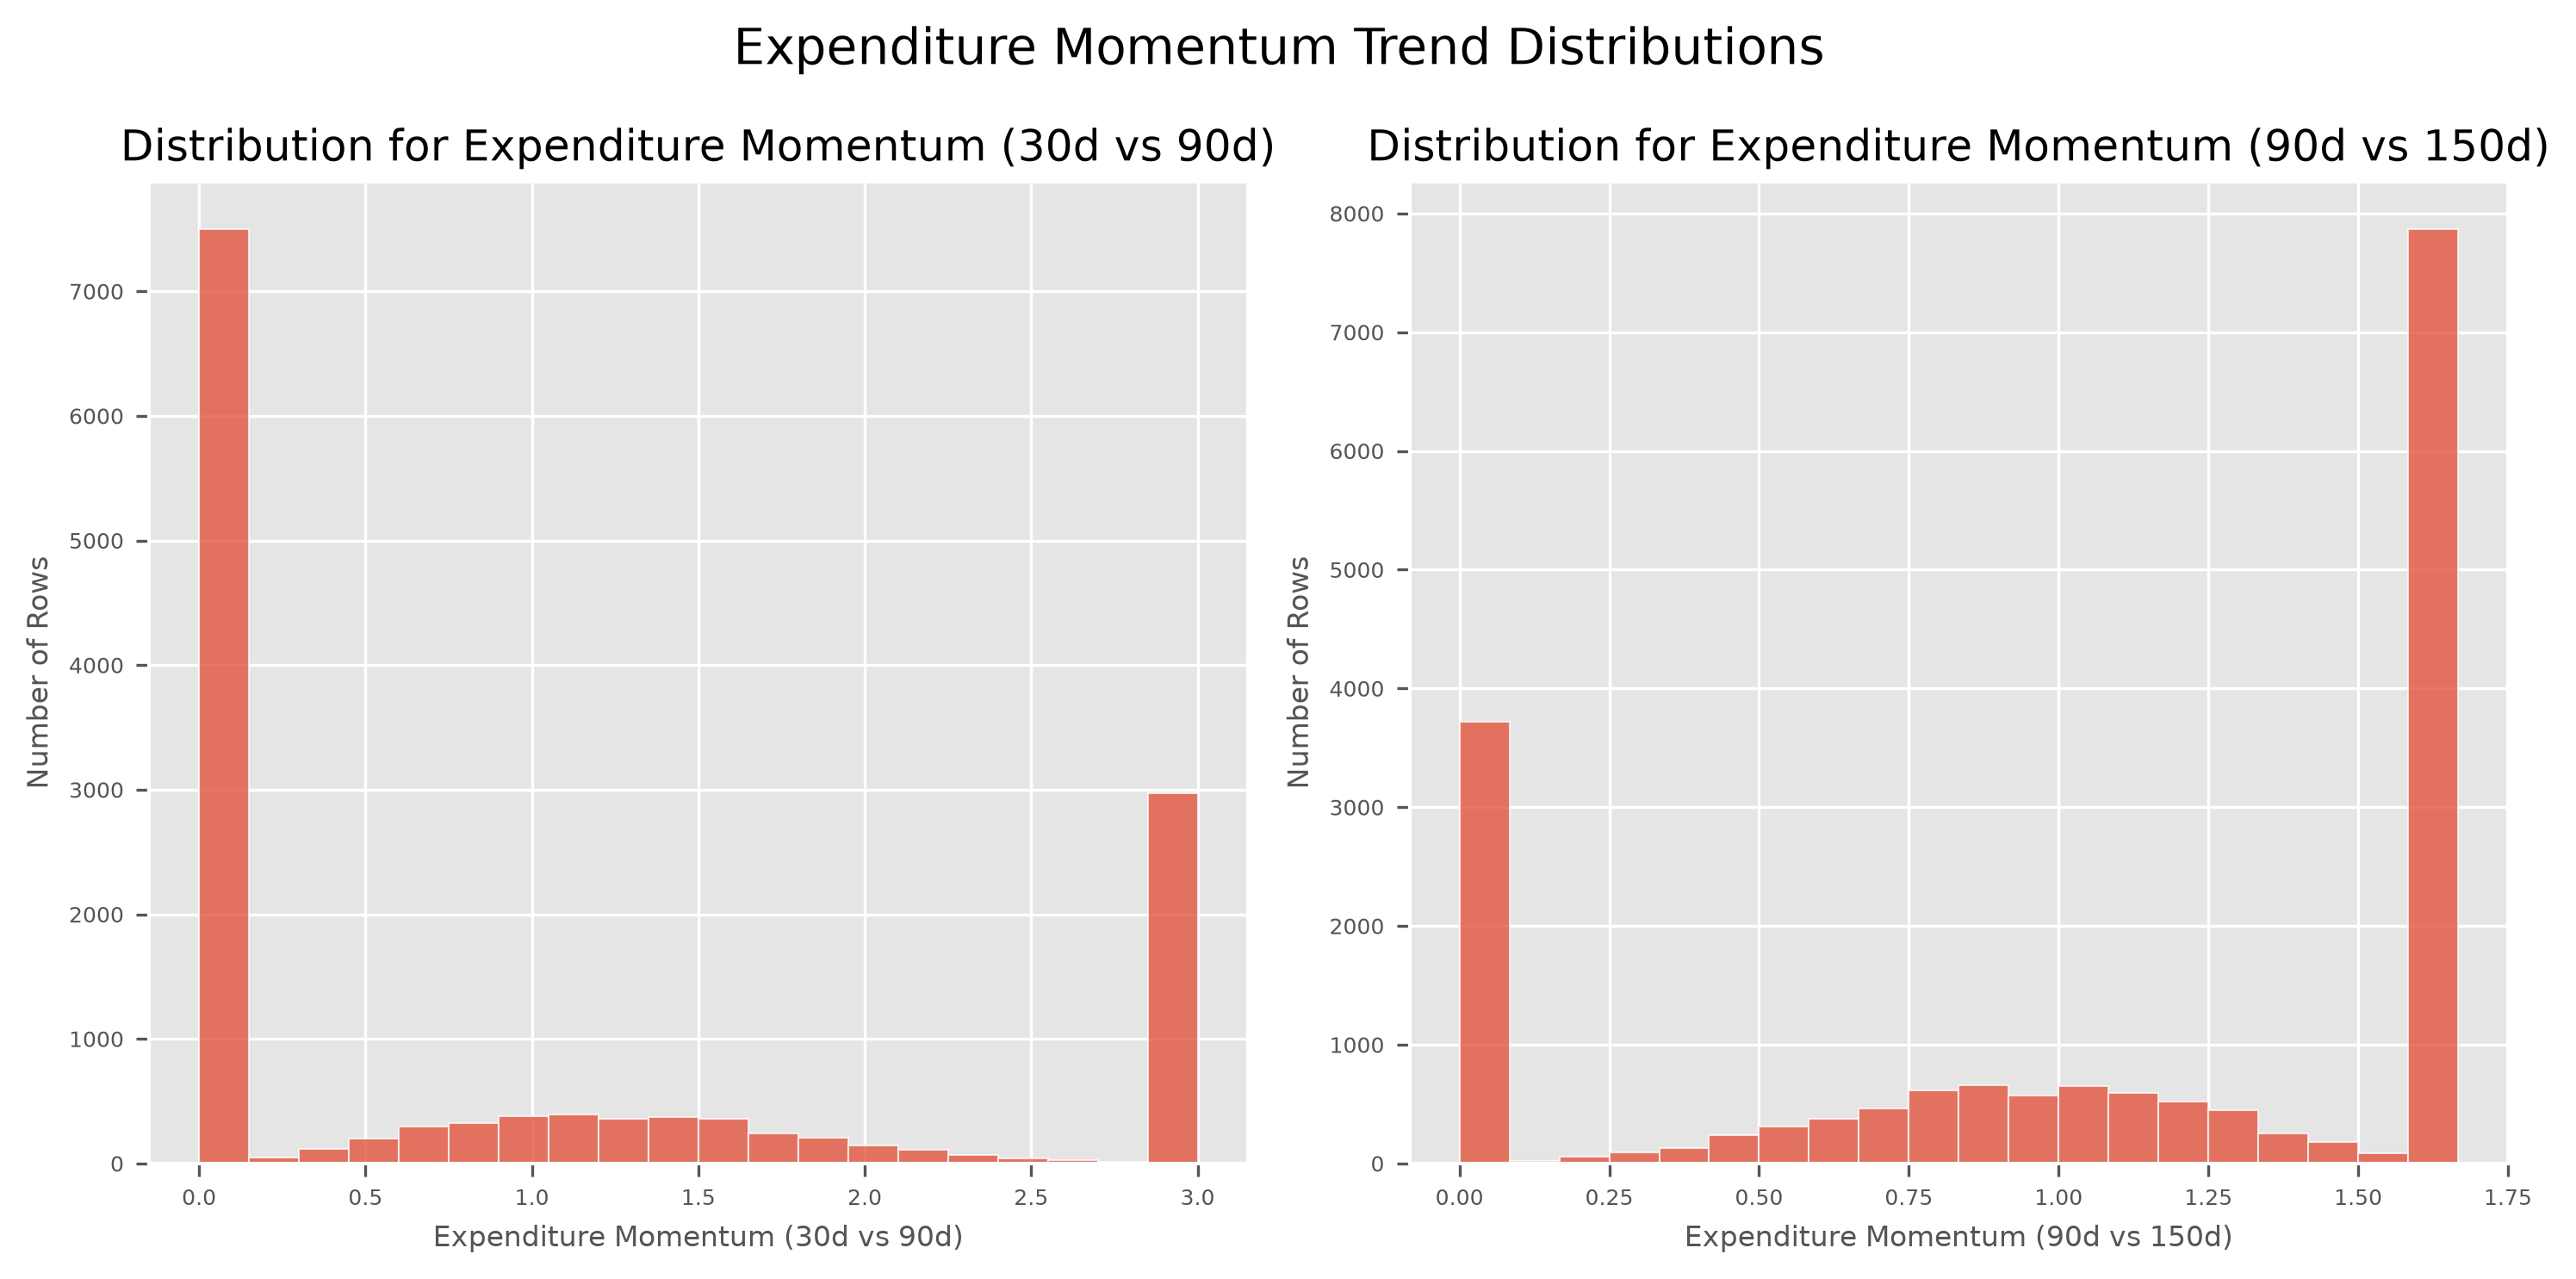

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5), dpi=300)

ax[0].hist(df["spend_momentum_30d_90d"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[0].set_xlabel(f"Expenditure Momentum (30d vs 90d)", fontsize=AXIS_LABELS)
ax[0].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[0].set_title(f"Distribution for Expenditure Momentum (30d vs 90d)", fontsize=GRAPH_TITLE)
ax[0].tick_params(axis="both", which="major", labelsize=TICKS)

ax[1].hist(df["spend_momentum_90d_150d"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[1].set_xlabel(f"Expenditure Momentum (90d vs 150d)", fontsize=AXIS_LABELS)
ax[1].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[1].set_title(f"Distribution for Expenditure Momentum (90d vs 150d)", fontsize=GRAPH_TITLE)
ax[1].tick_params(axis="both", which="major", labelsize=TICKS)

fig.suptitle("Expenditure Momentum Trend Distributions", fontsize=FIGURE_TITLE)
fig.tight_layout()

In [18]:
df[["orders_30d", "orders_90d", "orders_150d", "order_momentum_30d_90d", "order_momentum_90d_150d"]].describe()

,orders_30d,orders_90d,orders_150d,order_momentum_30d_90d,order_momentum_90d_150d
count,17857.000000,17857.000000,17857.000000,14152.000000,17857.000000
mean,0.549924,1.694182,2.661309,0.972203,1.063664
std,1.115018,2.647962,3.914933,1.199137,0.648394
min,0.000000,0.000000,1.000000,0.000000,0.000000
25%,0.000000,1.000000,1.000000,0.000000,0.666667
50%,0.000000,1.000000,2.000000,0.000000,1.176471
75%,1.000000,2.000000,3.000000,1.500000,1.666667
max,40.000000,80.000000,100.000000,3.000000,1.666667


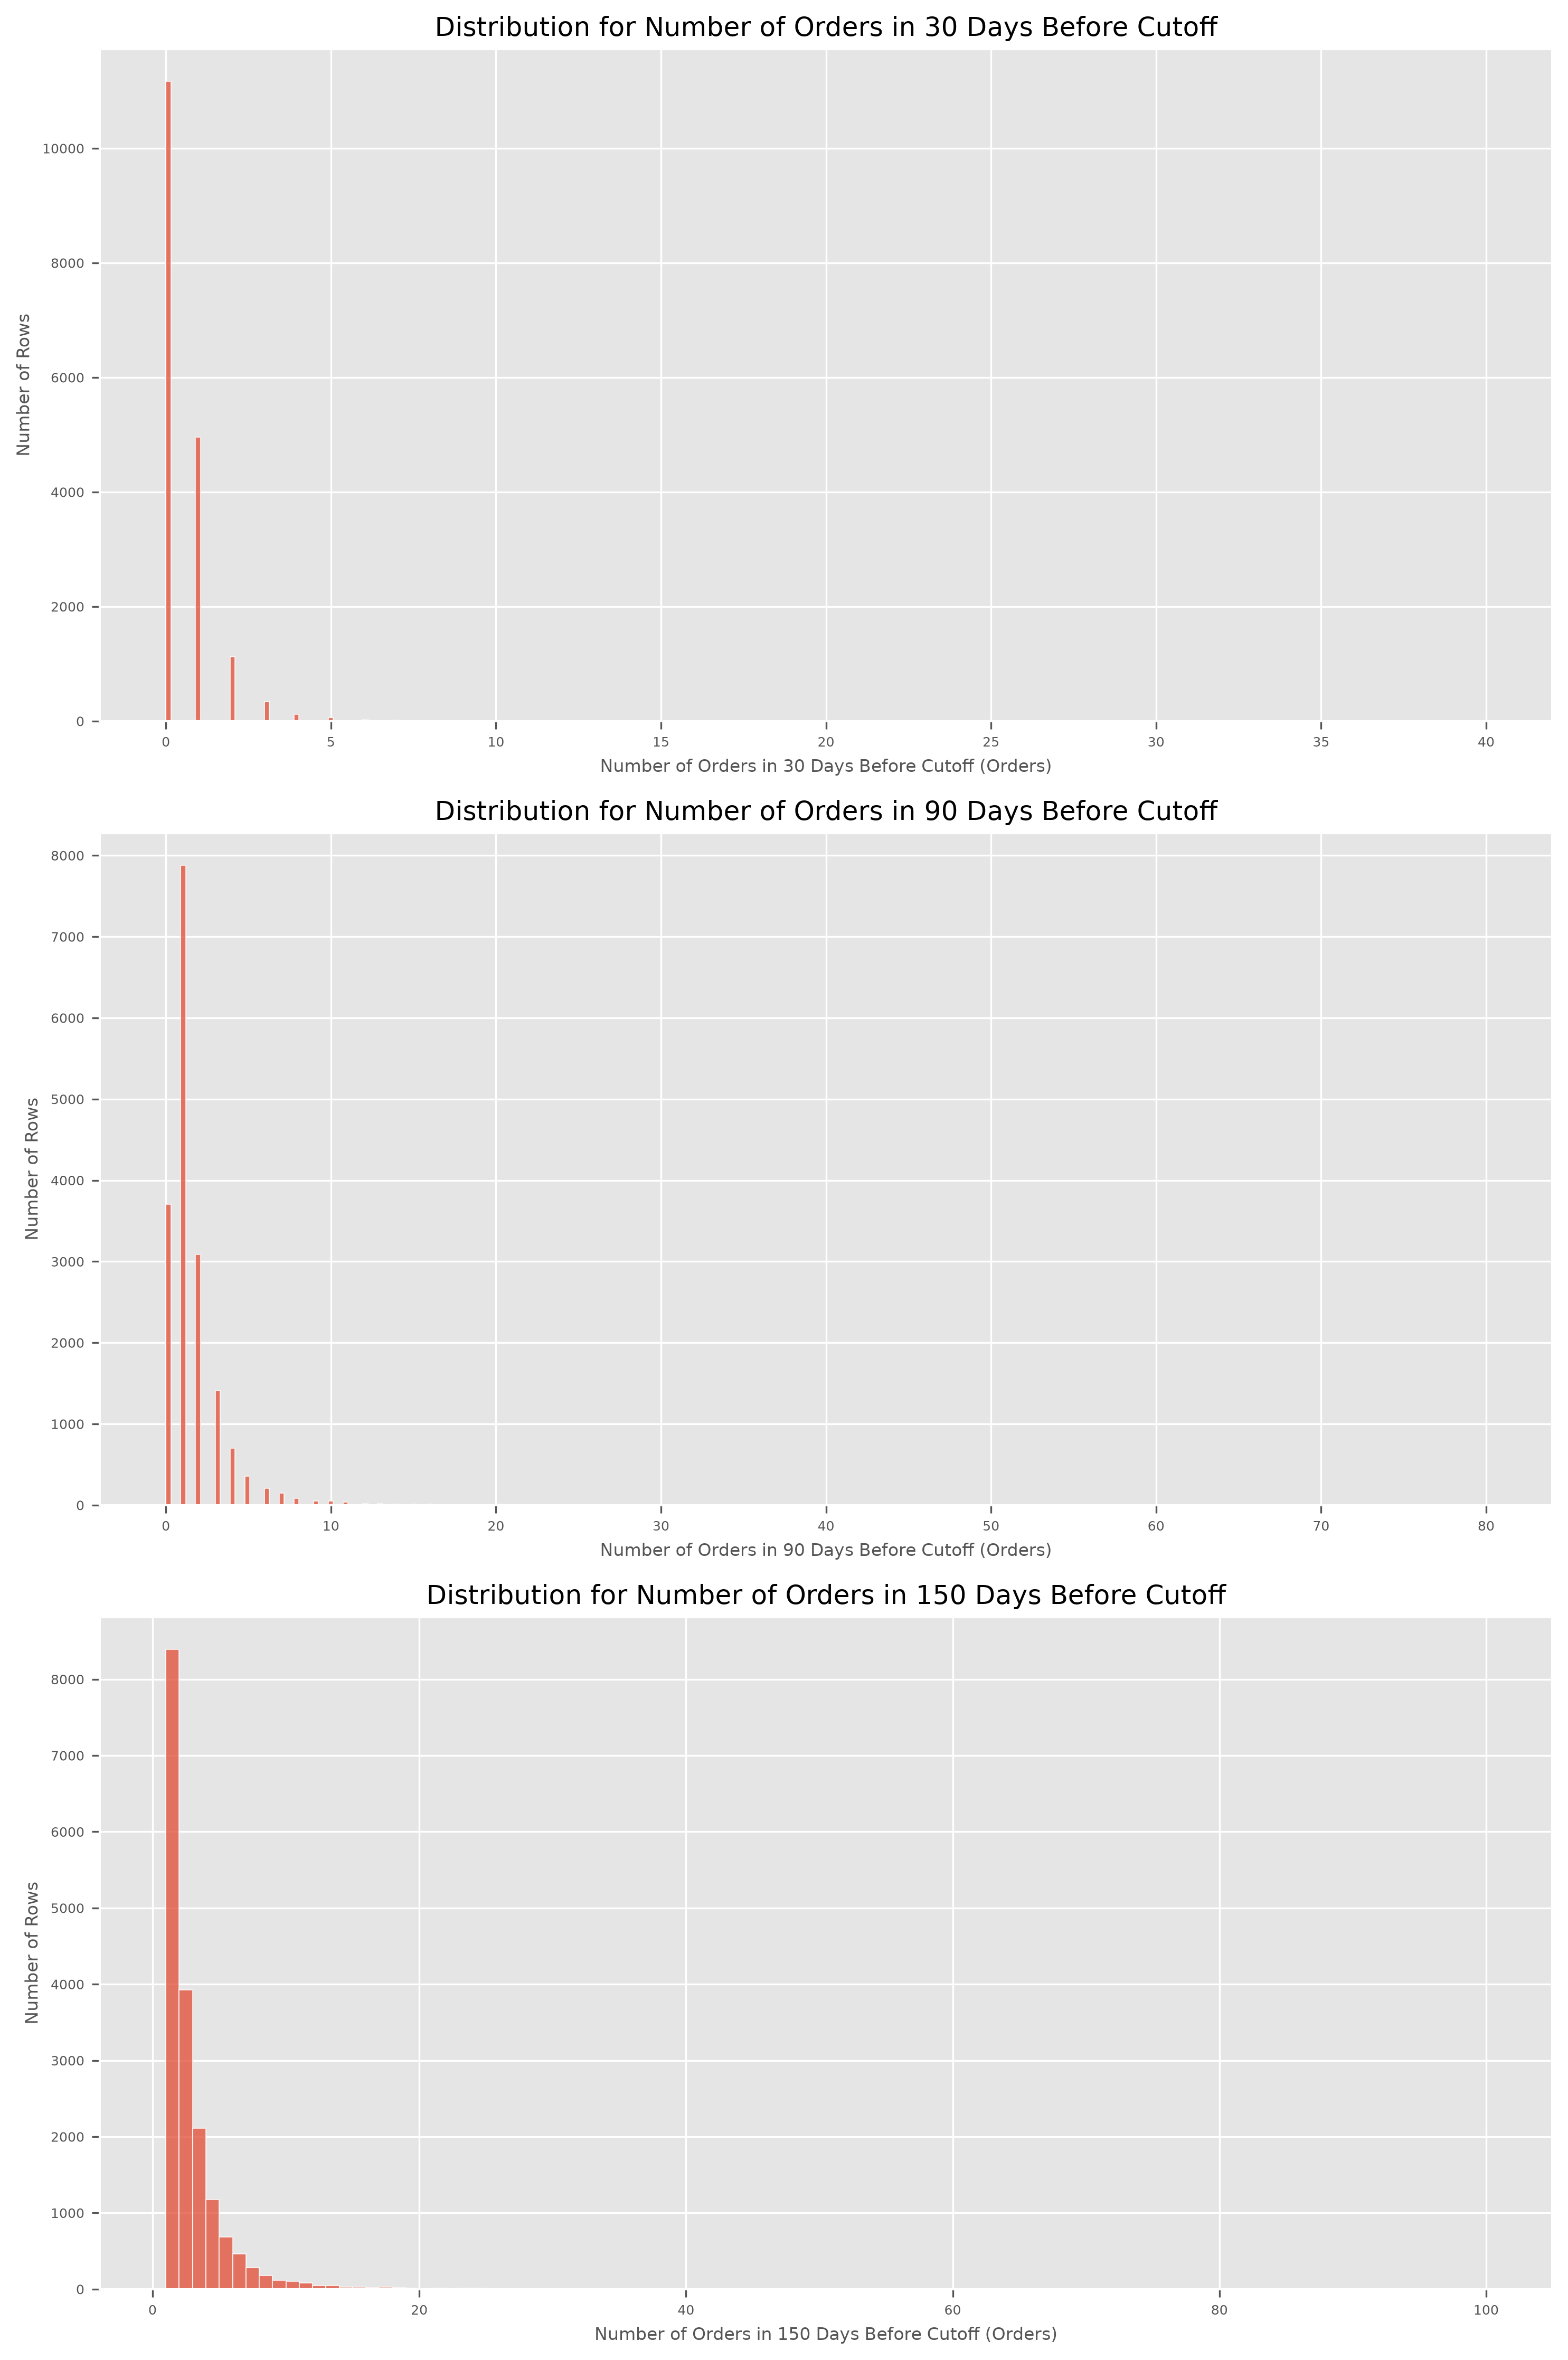

In [19]:
fig, ax = plt.subplots(3, 1, figsize=(10, 15), dpi=300)

ax[0].hist(df["orders_30d"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[0].set_xlabel(f"Number of Orders in 30 Days Before Cutoff (Orders)", fontsize=AXIS_LABELS)
ax[0].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[0].set_title(f"Distribution for Number of Orders in 30 Days Before Cutoff", fontsize=GRAPH_TITLE)
ax[0].tick_params(axis="both", which="major", labelsize=TICKS)

ax[1].hist(df["orders_90d"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[1].set_xlabel(f"Number of Orders in 90 Days Before Cutoff (Orders)", fontsize=AXIS_LABELS)
ax[1].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[1].set_title(f"Distribution for Number of Orders in 90 Days Before Cutoff", fontsize=GRAPH_TITLE)
ax[1].tick_params(axis="both", which="major", labelsize=TICKS)

ax[2].hist(df["orders_150d"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[2].set_xlabel(f"Number of Orders in 150 Days Before Cutoff (Orders)", fontsize=AXIS_LABELS)
ax[2].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[2].set_title(f"Distribution for Number of Orders in 150 Days Before Cutoff", fontsize=GRAPH_TITLE)
ax[2].tick_params(axis="both", which="major", labelsize=TICKS)

fig.tight_layout()

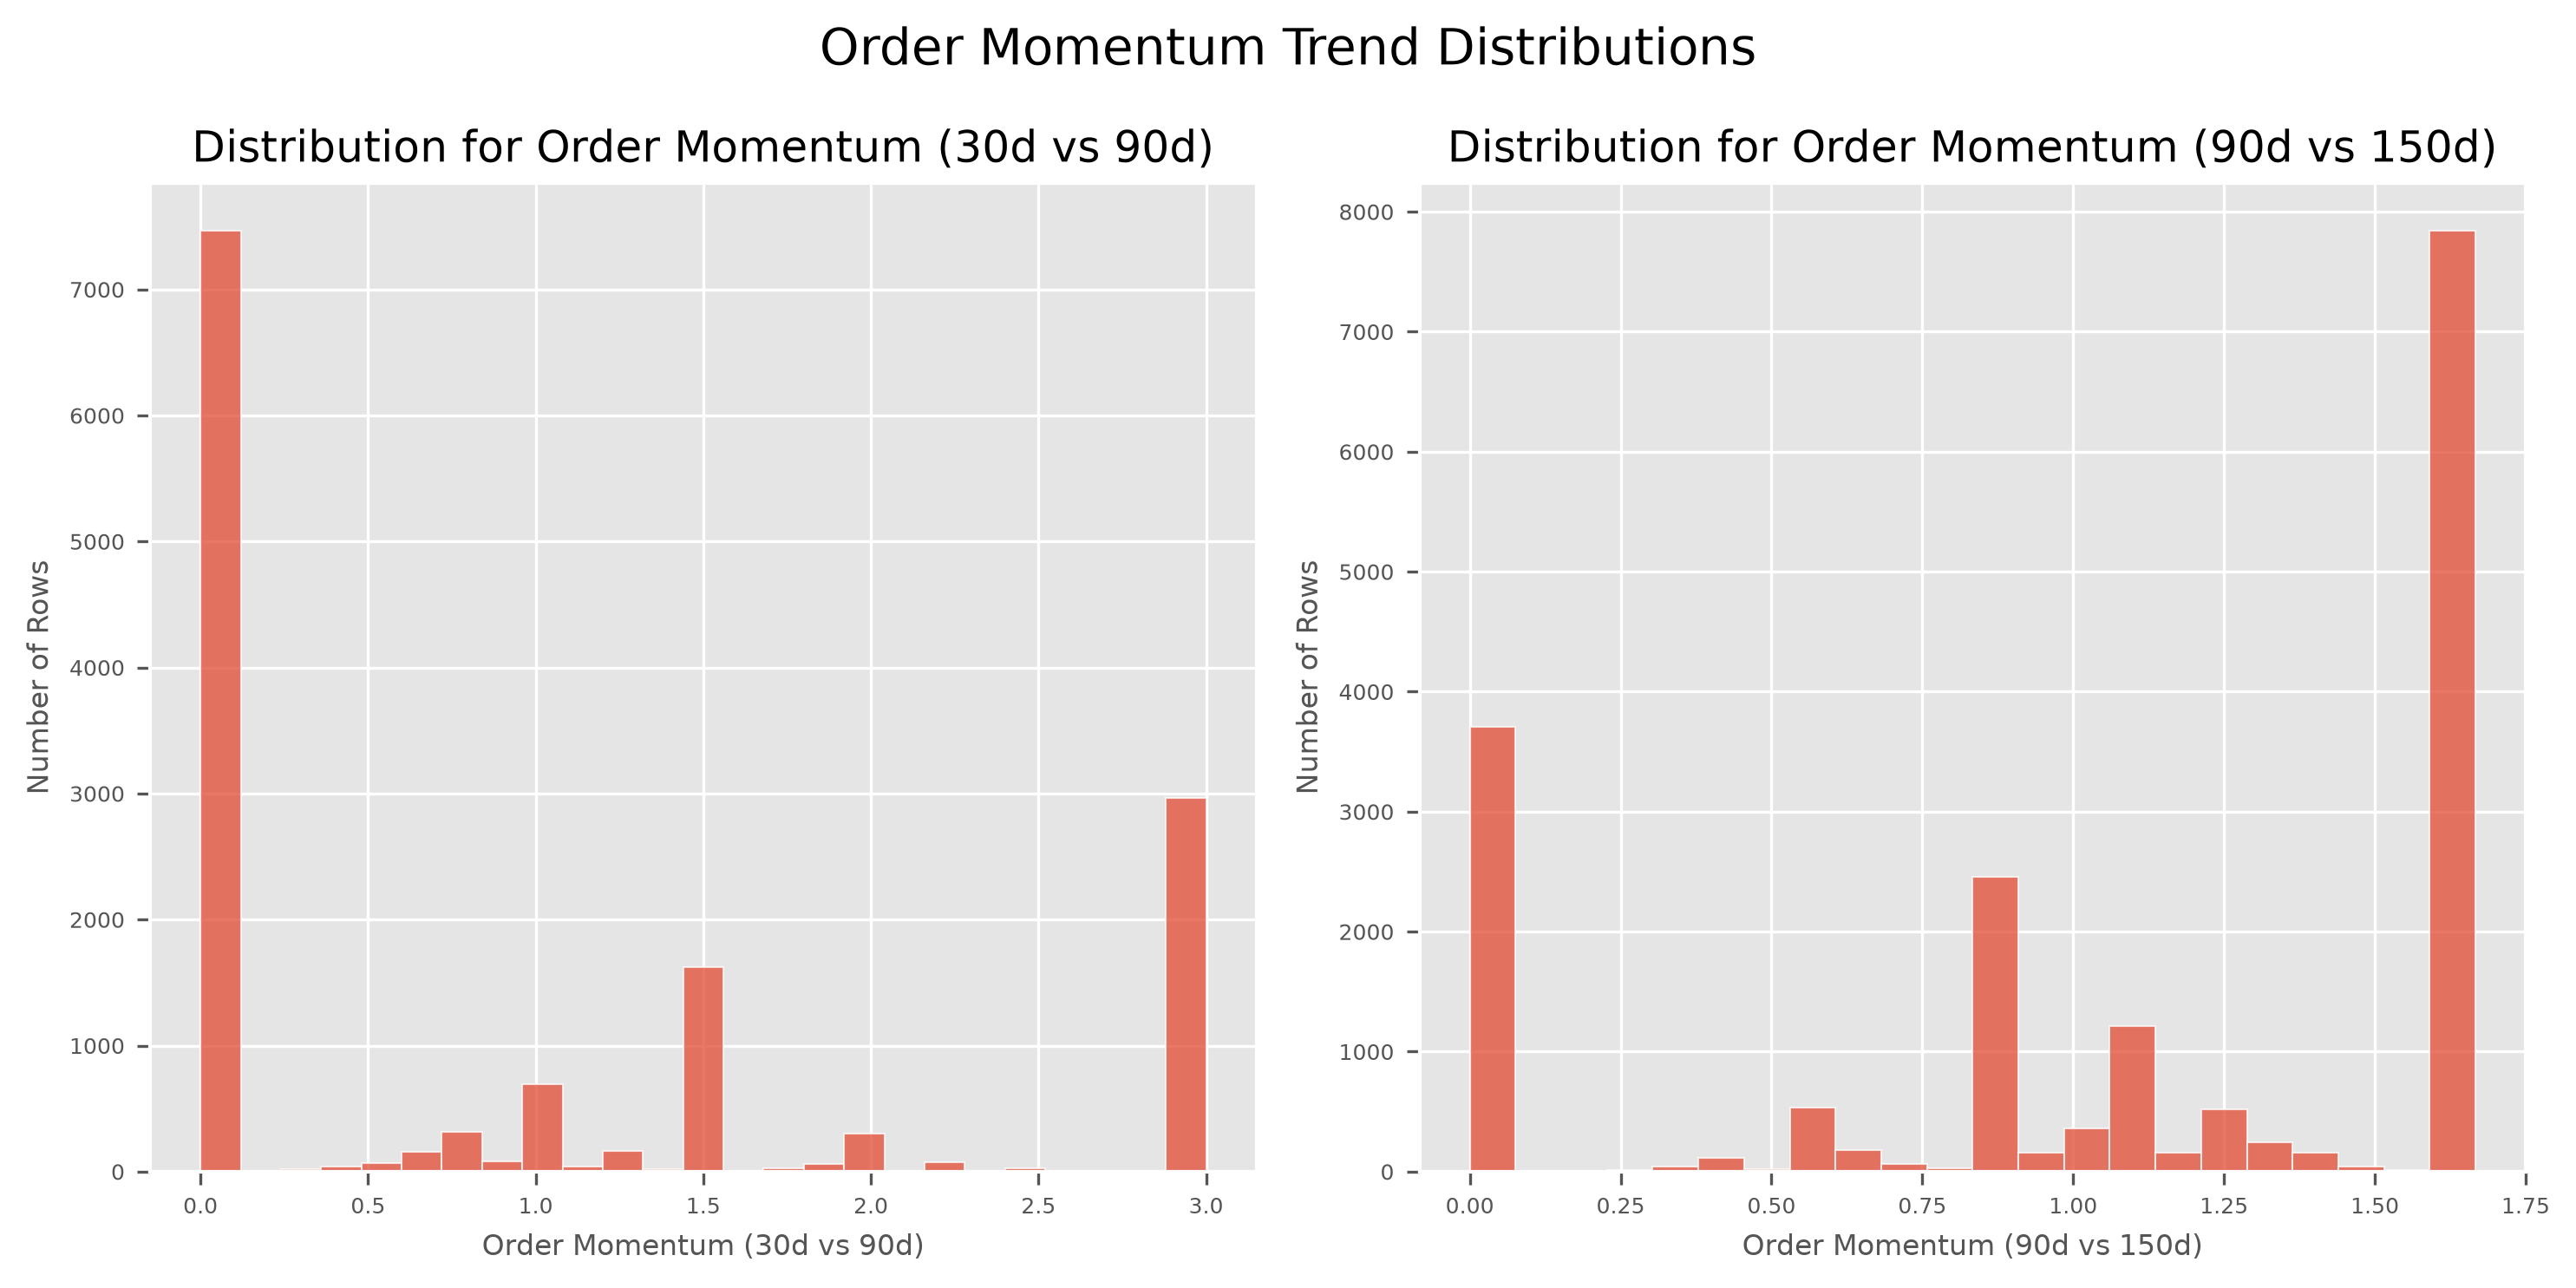

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5), dpi=300)

ax[0].hist(df["order_momentum_30d_90d"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[0].set_xlabel(f"Order Momentum (30d vs 90d)", fontsize=AXIS_LABELS)
ax[0].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[0].set_title(f"Distribution for Order Momentum (30d vs 90d)", fontsize=GRAPH_TITLE)
ax[0].tick_params(axis="both", which="major", labelsize=TICKS)

ax[1].hist(df["order_momentum_90d_150d"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[1].set_xlabel(f"Order Momentum (90d vs 150d)", fontsize=AXIS_LABELS)
ax[1].set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax[1].set_title(f"Distribution for Order Momentum (90d vs 150d)", fontsize=GRAPH_TITLE)
ax[1].tick_params(axis="both", which="major", labelsize=TICKS)

fig.suptitle("Order Momentum Trend Distributions", fontsize=FIGURE_TITLE)
fig.tight_layout()

### **Distinct Products**

In [21]:
df["distinct_products"].describe().to_frame()

,distinct_products
count,17857.000000
mean,77.137201
std,97.942475
min,1.000000
25%,22.000000
50%,48.000000
75%,98.000000
max,2052.000000


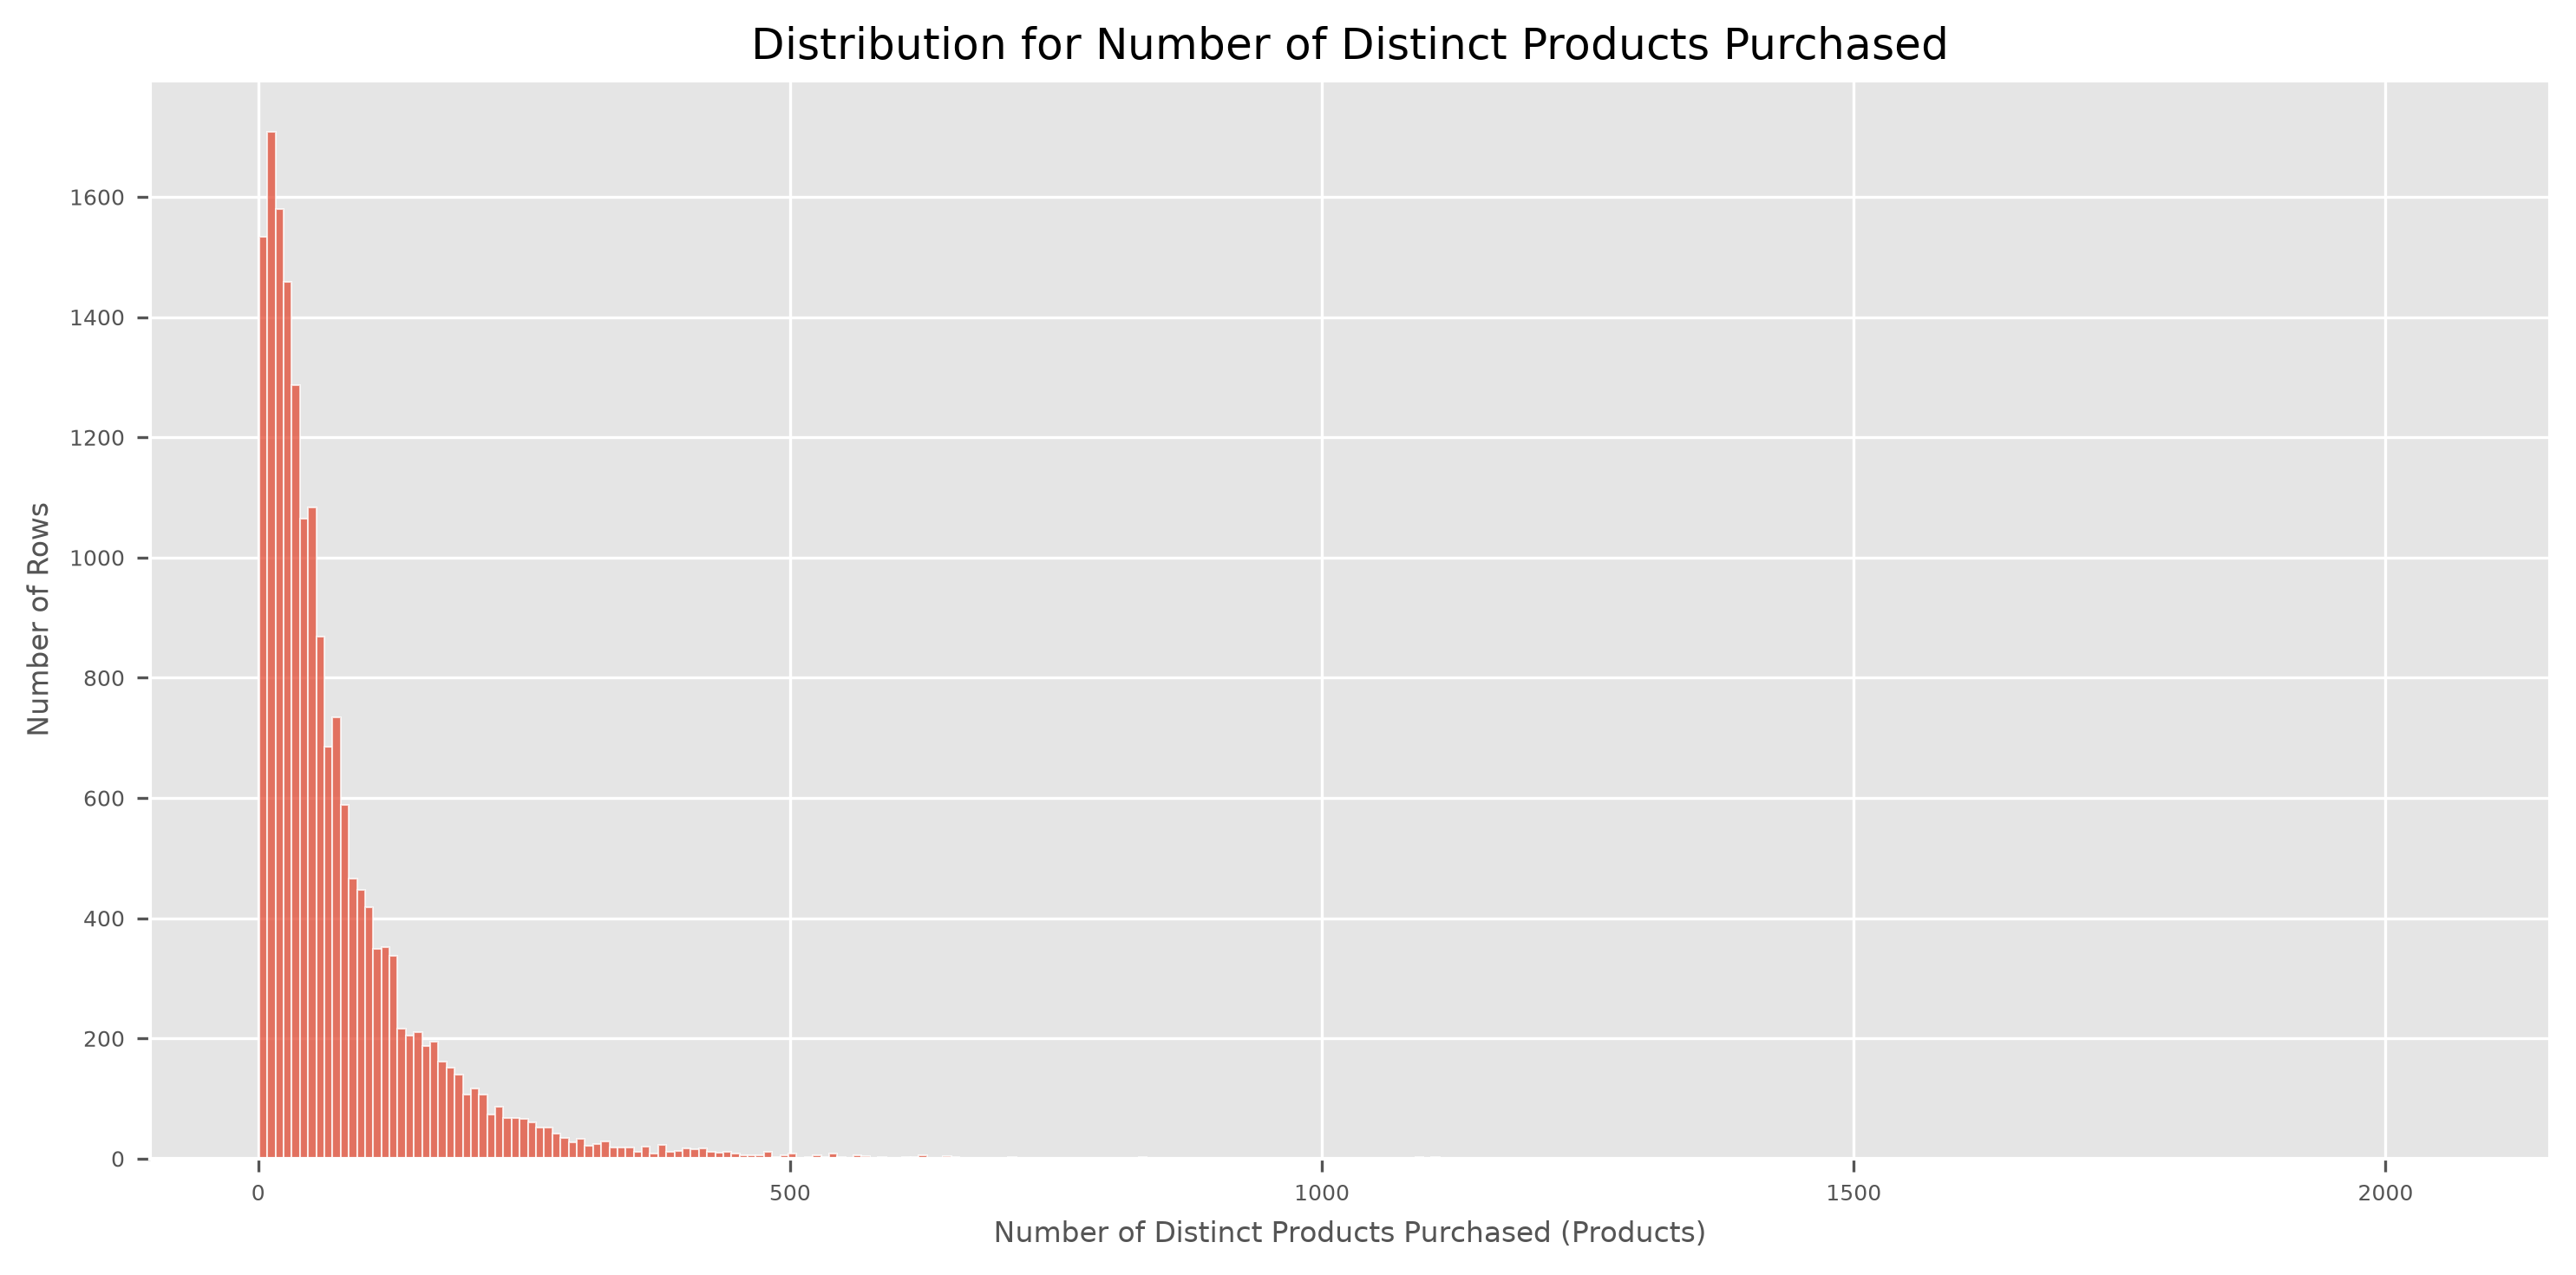

In [22]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.hist(df["distinct_products"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax.set_xlabel(f"Number of Distinct Products Purchased (Products)", fontsize=AXIS_LABELS)
ax.set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax.set_title(f"Distribution for Number of Distinct Products Purchased", fontsize=GRAPH_TITLE)
ax.tick_params(axis="both", which="major", labelsize=TICKS)
fig.tight_layout()

### **Mean Order Quantity**

In [23]:
df["mean_order_quantity"].describe().to_frame()

,mean_order_quantity
count,17857.000000
mean,267.883503
std,1560.048779
min,1.000000
25%,98.000000
50%,164.000000
75%,271.000000
max,87167.000000


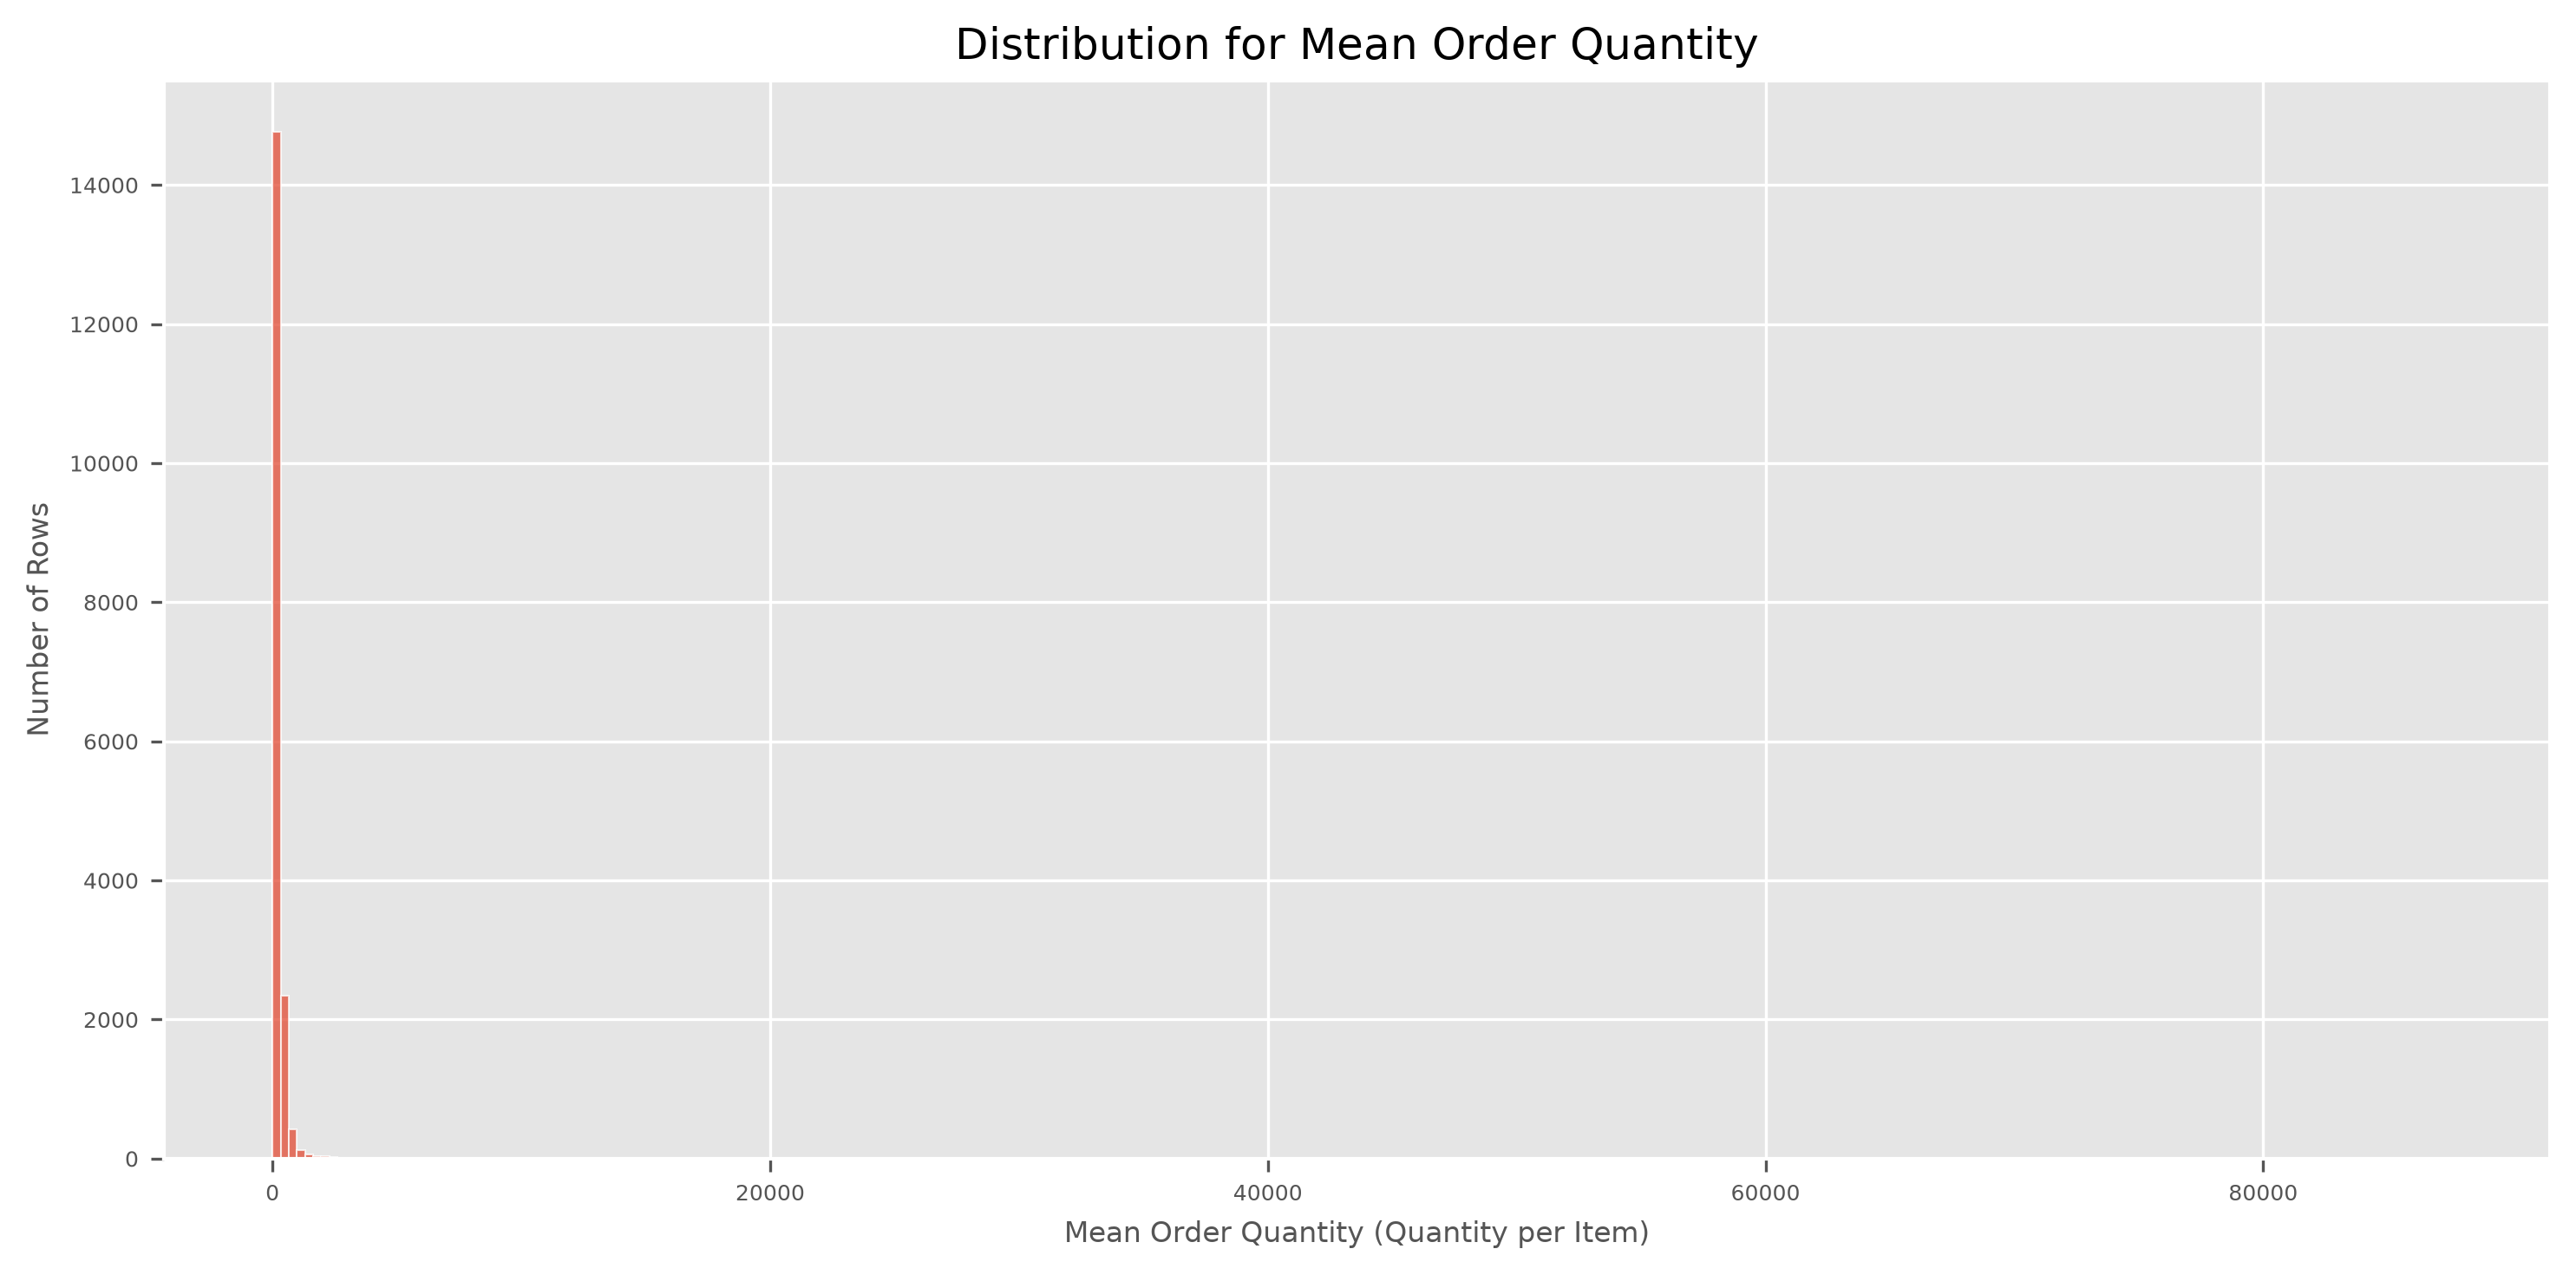

In [24]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.hist(df["mean_order_quantity"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax.set_xlabel(f"Mean Order Quantity (Quantity per Item)", fontsize=AXIS_LABELS)
ax.set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax.set_title(f"Distribution for Mean Order Quantity", fontsize=GRAPH_TITLE)
ax.tick_params(axis="both", which="major", labelsize=TICKS)
fig.tight_layout()

### **Return Rate**

In [25]:
df["return_rate"].describe().to_frame()

,return_rate
count,17857.000000
mean,0.124442
std,0.165894
min,0.000000
25%,0.000000
50%,0.000000
75%,0.250000
max,0.833333


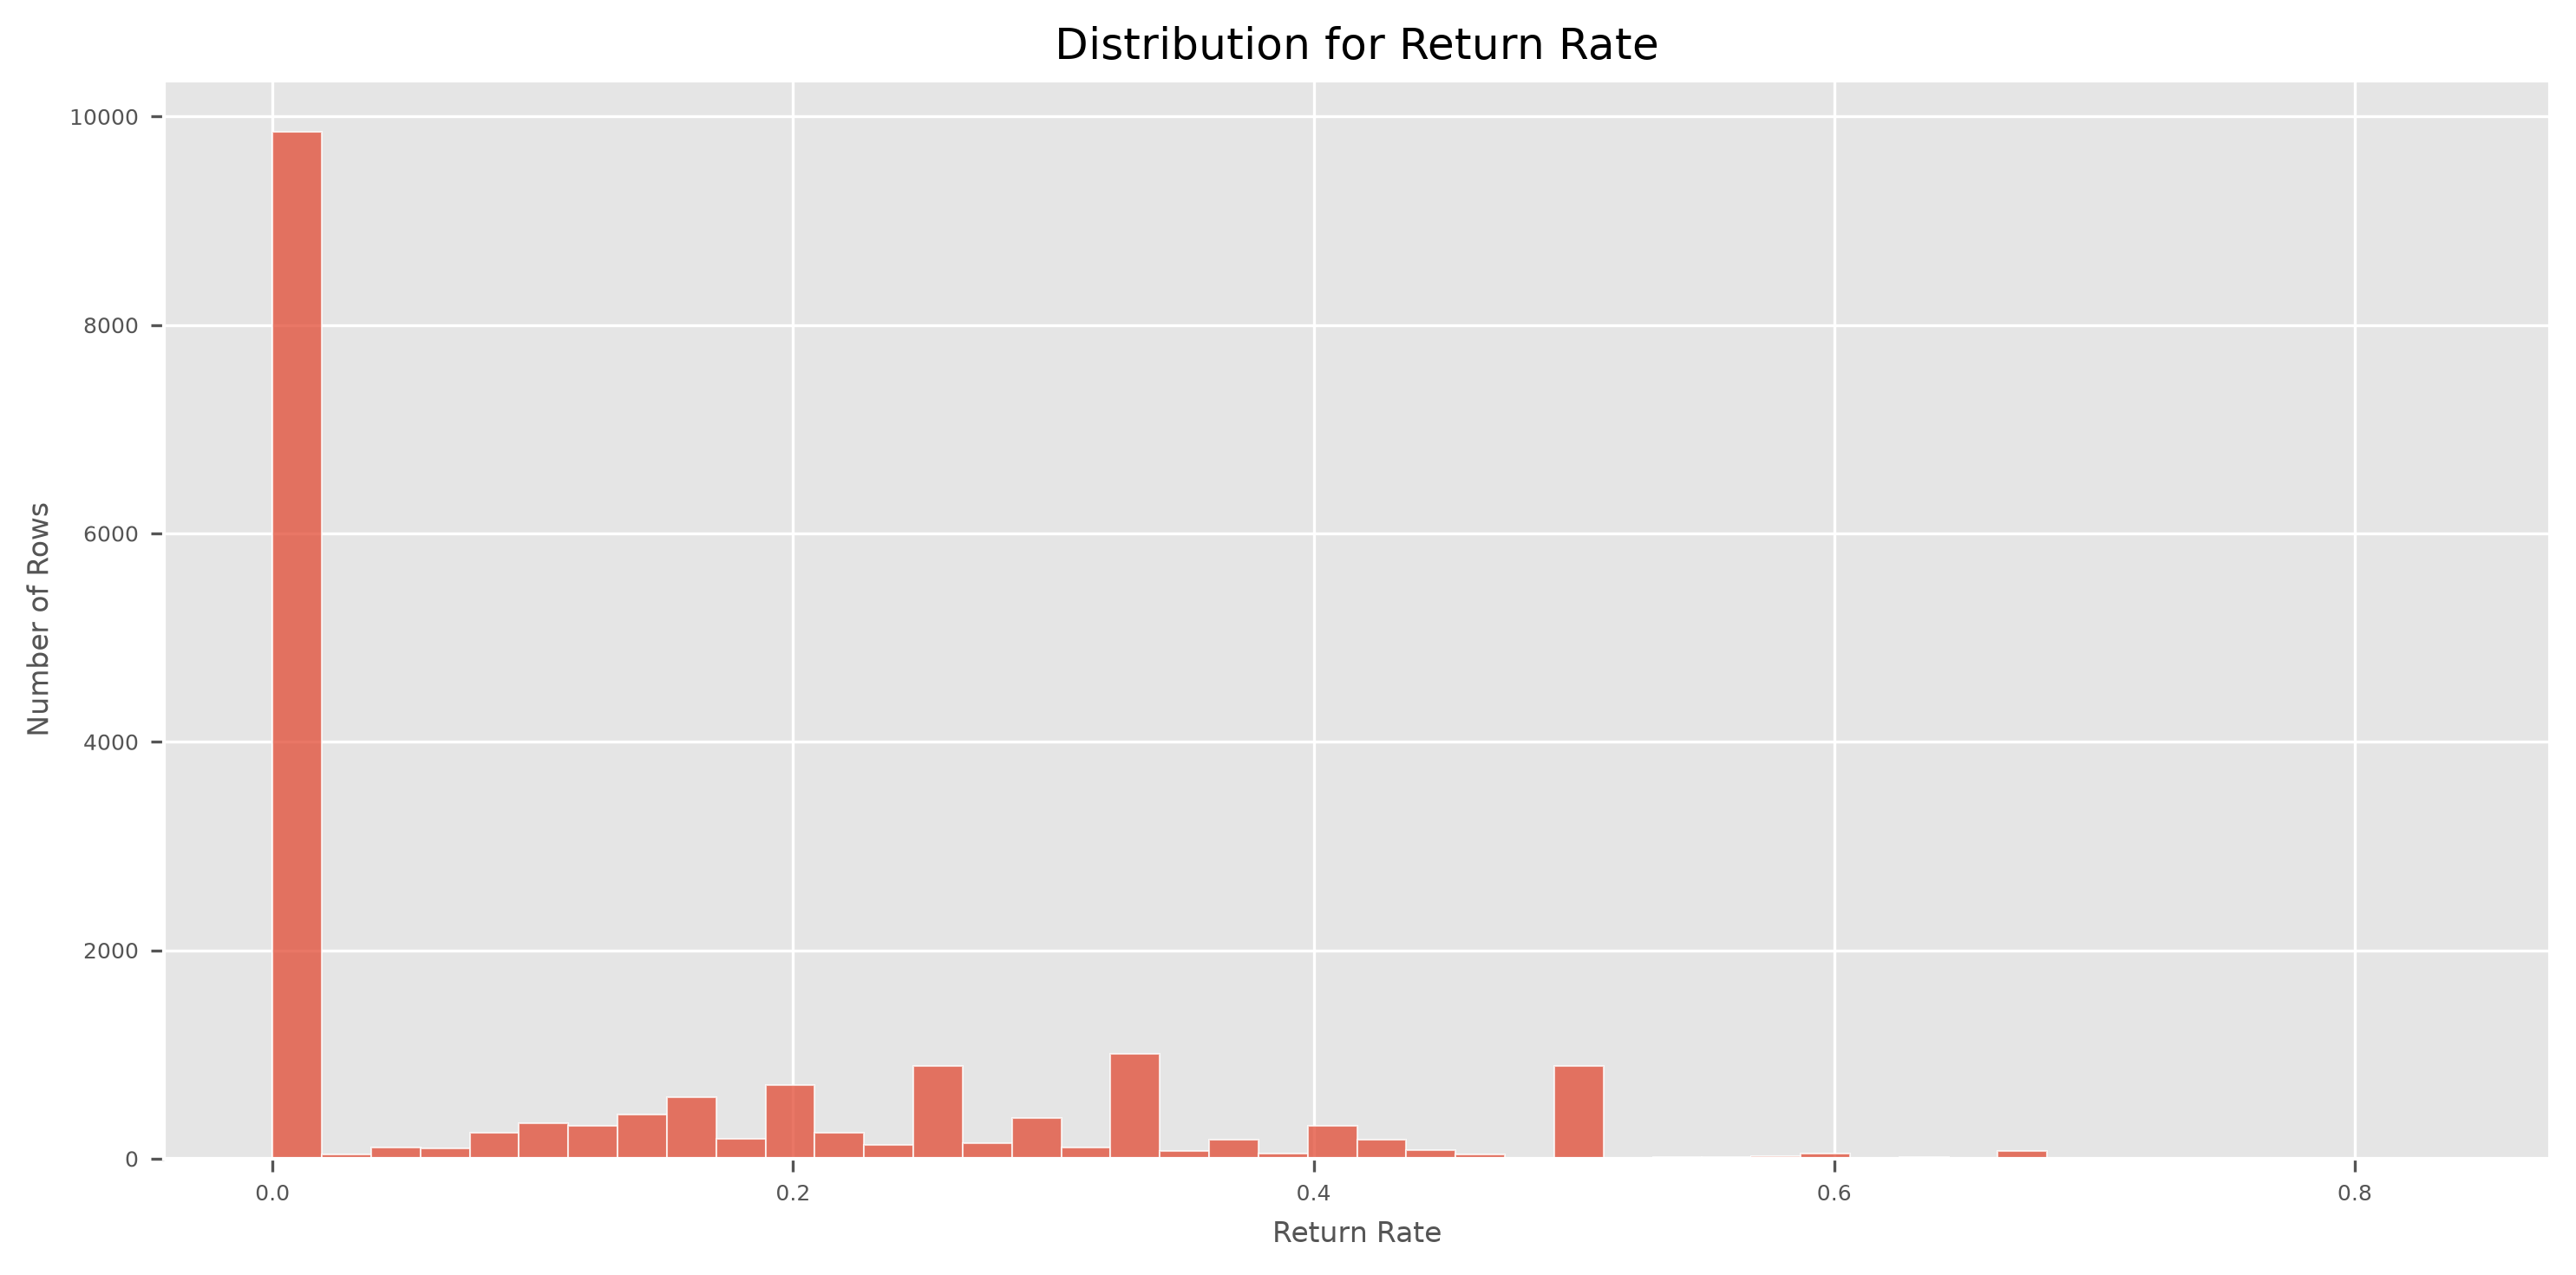

In [26]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.hist(df["return_rate"], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax.set_xlabel(f"Return Rate", fontsize=AXIS_LABELS)
ax.set_ylabel("Number of Rows", fontsize=AXIS_LABELS)
ax.set_title(f"Distribution for Return Rate", fontsize=GRAPH_TITLE)
ax.tick_params(axis="both", which="major", labelsize=TICKS)
fig.tight_layout()

### **Country**

In [27]:
raw_count = df["country"].value_counts().rename("Raw Count")
percentage = (df["country"].value_counts(normalize=True) * 100).rename("Percentage of Total")

df_country = pd.merge(raw_count, percentage, left_index=True, right_index=True)
df_country

,Raw Count,Percentage of Total
country,,
United Kingdom,16398,91.829535
Germany,296,1.657613
France,239,1.338411
Spain,93,0.520804
Belgium,85,0.476004
Netherlands,80,0.448004
Portugal,66,0.369603
Switzerland,66,0.369603
Australia,55,0.308002


### **Churned (Label)**

In [28]:
df["churned"].describe().to_frame()

,churned
count,17857.000000
mean,0.428011
std,0.494804
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [29]:
df.groupby("cutoff")["churned"].agg(["size", "mean"])

,size,mean
cutoff,,
2010-10-01,2669,0.353316
2010-11-01,2982,0.410127
2010-12-01,3283,0.490101
2011-01-01,3242,0.495990
2011-02-01,3135,0.473684
2011-07-12,2546,0.304399


## **Multivariate Analysis**

### **Country vs Churned**

In [30]:
df.assign(
    group=np.where(
        df.country == "United Kingdom", 
        df.country,
        np.where(
            df.country.isin(["Germany", "France"]), 
            df.country,
            "Other"
        )
    )
).groupby("group")["churned"].agg(["size", "mean"])

,size,mean
group,,
France,239,0.234310
Germany,296,0.280405
Other,924,0.458874
United Kingdom,16398,0.431760


### **Correlation Heatmap**

In [31]:
df_encoded = df.copy()
df_encoded["country"] = np.where(
    df_encoded.country.isin(["United Kingdom", "Germany", "France"]),
    df_encoded.country,
    "Others"
)
df_encoded = pd.get_dummies(df_encoded, columns=["country"], dtype=int)
df_encoded = df_encoded.drop(columns=["customer_id", "cutoff", "churn_horizon"])

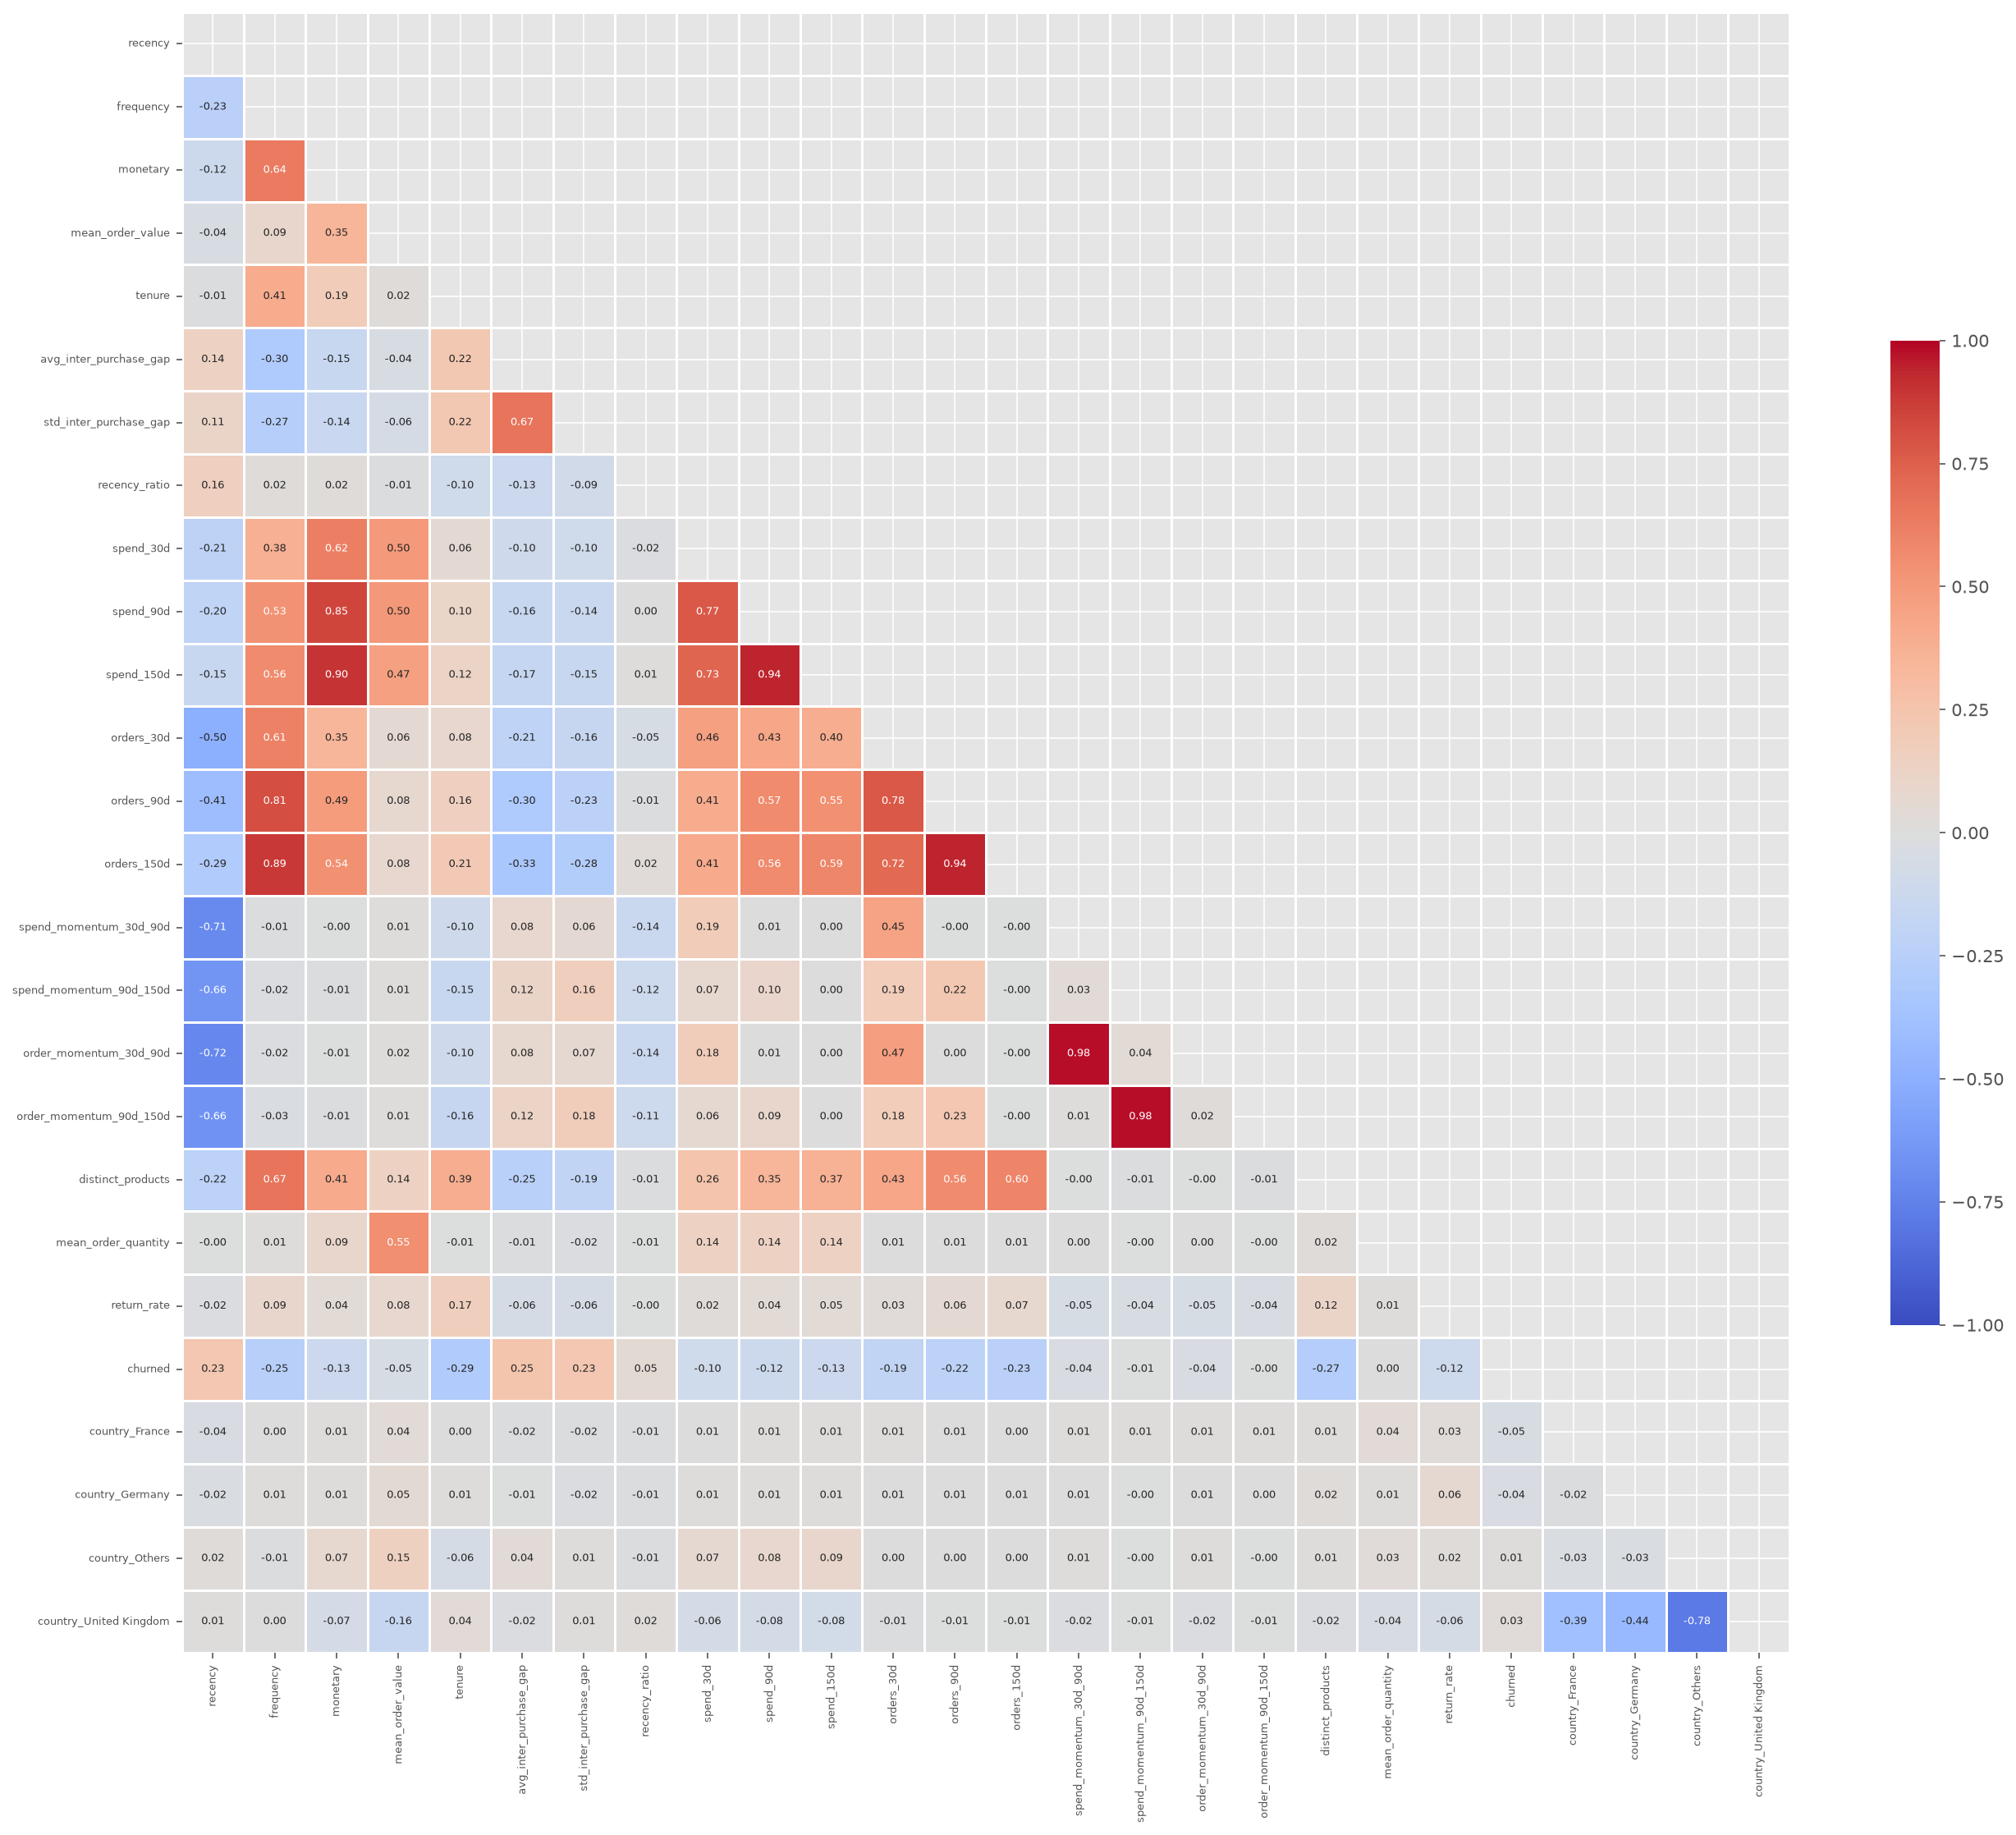

In [32]:
corr = df_encoded.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(18, 15), dpi=150)
sns.heatmap(
    corr, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    annot_kws={"size": TICKS},
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    center=0,
    linewidths=0.5, 
    cbar_kws={"shrink": 0.6}, 
    ax=ax)
ax.tick_params(labelsize=TICKS)

fig.tight_layout() 

## **Summary of Findings**

### **Imputing Method for NaN Values**

Given that the all the NaN values are structurally rooted in feature engineering decisions, filling with the median value for their cutoff group with an ```add_indicator=True``` flag will sufficiently preserve the reason for their existence without creating unnecessary noise.

### **Features Requiring Numerical Transformation (np.log1p)**

The following features have maximum values that far exceed their median values, requiring log transformation before scaling:

- frequency

- monetary

- mean_order_value

- avg_inter_purchase_gap

- std_inter_purchase_gap

- recency_ratio

- spend_30d

- spend_90d

- spend_150d

- orders_30d

- orders_90d

- orders_150d

- distinct_products

- mean_order_quantity

### **Country OneHotEncoding**

Despite Germany and France making up 1.68% and 1.45% of the total number of rows respectively (significantly smaller than the United Kingdom, and just above the 1% cutoff that filters the "other" countries), they provide significantly different churned signals from the rest of the filtered countries. **They should therefore remain as OneHotEncoded features in model fitting.**